# Détection et atténuation des hallucinations dans un système RAG via l'inférence en langage naturel (NLI)

**Projet NLP / LLM — Sujet n°15 : « Hallucination Detection and Mitigation in RAG » (avancé)**

> **Auteur :** Mazen Ben Brahim *(travail individuel)*
>
> **Cadre :** projet universitaire — sujet n°15 « Hallucination Detection and Mitigation in RAG » — enseignante : **Mme Tasnim Hamdeni**.
>
> **Environnement d'exécution recommandé :** Google Colab avec GPU T4 (Runtime → Change runtime type → T4 GPU). Le notebook s'exécute de haut en bas sans intervention ; comptez **≈ 40–50 minutes** au total sur T4 (téléchargement des modèles inclus).
>
> **Jeu de données :** [RAGTruth](https://github.com/ParticleMedia/RAGTruth), via le miroir Hugging Face [`wandb/RAGTruth-processed`](https://huggingface.co/datasets/wandb/RAGTruth-processed) (licence MIT).
>
> **Transparence sur l'usage de l'IA :** ce notebook a été développé avec l'assistance de l'outil Claude Code (Anthropic) comme assistant de programmation, sous la direction de l'étudiant qui a choisi les méthodes, validé chaque étape et rédigé les analyses. Conformément à la consigne du cours, cette utilisation substantielle d'un LLM est mentionnée ici et détaillée en section 8.

---

## Sommaire

1. **Introduction et problématique**
2. **État de l'art et notions clés**
3. **Données et préparation**
4. **Méthodologie et code** (pipeline RAG, détecteur NLI, détecteur LLM-juge, boucle de mitigation)
5. **Résultats**
6. **Interprétation et analyse critique**
7. **Conclusion**
8. **Références**

# 1. Introduction et problématique

## 1.1 Le contexte : les systèmes RAG

Un système **RAG** (*Retrieval-Augmented Generation*, Lewis et al., 2020) combine deux modules :

1. un **module de récupération** (*retrieval*) qui, pour une question donnée, cherche les passages les plus pertinents dans une base documentaire — ici grâce à des **embeddings denses** et à l'index de similarité **FAISS** ;
2. un **générateur** (un LLM) qui rédige la réponse **conditionnée sur ces passages récupérés**, ce qui devrait ancrer la réponse dans des sources externes et à jour.

## 1.2 Le problème : l'hallucination

Malgré cet ancrage, le LLM produit fréquemment des affirmations qui **ne sont pas soutenues par les passages récupérés** : c'est ce qu'on appelle une **hallucination** (Ji et al., 2023). Une hallucination n'est pas forcément fausse dans l'absolu — c'est une affirmation **non soutenue par la source**, ce qui est le bon critère quand on veut un système traçable : ce qui n'est pas vérifiable dans les sources ne devrait pas être affirmé. Ce phénomène limite gravement la fiabilité des systèmes RAG dans les contextes sensibles (médical, juridique, éducatif).

Les approches de détection les plus répandues reposent sur un **« LLM-juge »** : on demande à un autre LLM (ou au même) de relire la réponse et de signaler ce qui n'est pas soutenu. Cette approche fonctionne, mais elle est **coûteuse** (un appel LLM par réponse jugée), **lente**, peu **explicable**, et sa fiabilité **dépend fortement du prompt** et de biais documentés du juge (Zheng et al., 2023).

## 1.3 L'approche de ce projet

Ce projet ancre la détection dans une tâche NLP classique, bien définie et peu coûteuse : l'**inférence en langage naturel** (*Natural Language Inference*, NLI), réalisée par un modèle encodeur de petite taille (DeBERTa-v3-base, ~184 M de paramètres, contre ~3 000 M pour notre LLM). Le pipeline complet est :

```
 Question ──► Récupération FAISS (top-k passages) ──► Génération LLM (réponse RAG)
                                                             │
                                                             ▼
                              ┌──────────────────────────────┴───────────────┐
                              │   DÉTECTION des hallucinations, phrase par   │
                              │   phrase, par DEUX méthodes comparées :      │
                              │  1) Détecteur NLI (DeBERTa-MNLI)  2) LLM-juge│
                              └──────────────────┬───────────────────────────┘
                                                 ▼
                      MITIGATION : régénération contrainte des phrases signalées
                      (réécriture strictement appuyée sur les passages, ou suppression)
                                                 ▼
                        Re-vérification NLI + évaluation avant / après
```

## 1.4 Questions de recherche

- **RQ1.** Un détecteur basé NLI peut-il identifier les hallucinations avec une précision/rappel **comparable ou supérieure** à un LLM-juge, à un **coût et une latence très inférieurs** ?
- **RQ2.** Les deux méthodes sont-elles **d'accord sur les mêmes cas** (accord inter-juges, coefficient κ de Cohen), ou détectent-elles des **types d'hallucinations différents** ?
- **RQ3.** Une **boucle de régénération contrainte** réduit-elle significativement le taux d'hallucinations de la réponse finale, et à quel **coût supplémentaire** (latence, tokens) ?
- **RQ4.** Quelles sont les **limites** de la détection au niveau de la **phrase** (hallucinations réparties sur plusieurs phrases, nuances de sens, négations) ?

# 2. État de l'art et notions clés

## 2.1 Hallucinations dans la génération et dans le RAG

La taxonomie usuelle (Ji et al., 2023) distingue les hallucinations **intrinsèques** (la sortie contredit ou détourne la source fournie) et **extrinsèques** (la sortie introduit une information sans fondement dans la source — sans être forcément fausse dans le monde réel). RAGTruth (Niu et al., 2024), le corpus utilisé ici, affine cette distinction avec des annotations **au niveau du span** et deux familles : *Evident/Subtle Conflict* (contradiction de la source) et *Evident/Subtle Baseless Info* (information sans appui dans la source).

Côté détection, trois familles de méthodes dominent la littérature :

1. **Vérification par NLI** — le couple (passage source, affirmation) est soumis à un modèle d'inférence en langage naturel entraîné sur MNLI (Williams et al., 2018). C'est la base des systèmes **SummaC** (Laban et al., 2022) et du benchmark **TRUE** (Honovich et al., 2022), qui ont montré qu'un petit modèle NLI bien utilisé rivalise avec de gros modèles sur la cohérence factuelle — à une fraction du coût.
2. **LLM-juge** — un LLM est prompté pour noter ou étiqueter chaque affirmation (approche popularisée par MT-Bench ; Zheng et al., 2023). Flexible et nuancé, mais coûteux, lent, sensible au prompt, et sujet à des biais documentés (préférence pour son propre style, verbosité, position de la réponse).
3. **Méthodes statistiques sur les probabilités du générateur** (SelfCheckGPT, etc.) — inapplicables ici car nous voulons vérifier une réponse **après coup**, sans accès garanti aux logits de génération.

Notre projet compare expérimentalement **(1)** et **(2)** sur les mêmes données — une comparaison systématique plutôt qu'une application isolée, conformément à la démarche scientifique demandée.

## 2.2 Notions clés avant de lire le code

### a) NLI : entailment / neutral / contradiction

La **NLI** (*Natural Language Inference*) prend deux textes en entrée :

- la **prémisse** : ici, un passage récupéré (la source de vérité) ;
- l'**hypothèse** : ici, une phrase de la réponse générée.

et classe leur relation en trois catégories :

| Relation | Signification | Exemple (prémisse = « Le magasin est ouvert de 9 h à 18 h ») |
|---|---|---|
| **entailment** (inférence) | la prémisse **confirme** l'hypothèse | « Le magasin ouvre à 9 h. » |
| **neutral** (neutre) | la prémisse **ne dit rien** qui permette de trancher | « Le magasin vend des meubles. » |
| **contradiction** | la prémisse **contredit** l'hypothèse | « Le magasin ouvre à 10 h. » |

**Application à la détection :** une phrase de la réponse est *soutenue* si **au moins un** passage l'entraîne (entailment). Elle est une *hallucination potentielle* si aucun passage ne l'entraîne (max des scores d'entailment sous un seuil τ) ou si un passage la contredit (score de contradiction dominant). C'est l'agrégation « **max sur les passages** » : face à plusieurs sources, il suffit qu'une seule soutienne l'affirmation.

### b) Embeddings denses et FAISS

Un **embedding** est la représentation vectorielle d'un texte produite par un modèle encodeur (ici `all-MiniLM-L6-v2`, entraîné pour que des textes de sens proche aient des vecteurs proches — Reimers & Gurevych, 2019). En normalisant les vecteurs, le produit scalaire devient la **similarité cosinus** entre textes. **FAISS** (Johnson et al., 2019) est une bibliothèque de recherche de plus proches voisins dans cet espace : nous utilisons `IndexFlatIP`, une recherche **exacte** par produit scalaire interne — adaptée à notre taille de corpus (~10³ documents) et simple à justifier.

### c) Pourquoi le coefficient κ de Cohen plutôt qu'un simple pourcentage d'accord ?

Si deux détecteurs prédisent « hallucination » sur seulement 5 % des phrases, ils seront d'accord **au moins 90 % du temps en prédisant tous deux « non »** par pur hasard. Un taux d'accord brut est donc trompeur dès que les classes sont déséquilibrées. Le **κ de Cohen** (Cohen, 1960) corrige ce biais en retranchant l'accord attendu par chance :

**κ = (p₀ − pₑ) / (1 − pₑ)** où *p₀* = accord observé, *pₑ* = accord attendu sous indépendance des juges.

Interprétation usuelle (Landis & Koch) : < 0 désaccord ; 0–0,20 très faible ; 0,21–0,40 faible ; 0,41–0,60 modéré ; 0,61–0,80 substantiel ; 0,81–1 presque parfait.

### d) Fidélité (*faithfulness*) vs vérité (*factuality*)

Dans tout ce notebook, « fidèle » signifie **soutenu par les passages récupérés** — et non « vrai dans le monde réel ». Un système RAG doit d'abord être fidèle à ses sources ; obtenir des faits vrais exige en plus que la récupération apporte les bons passages. La confusion entre ces deux notions est une limite classique que nous discutons en section 6.

# 3. Données et préparation

## 3.0 Environnement d'exécution et configuration

La section Données étant la première du notebook à exécuter du code, elle commence par la mise en place de l'environnement : installation des dépendances, imports, **cellule de configuration centrale** (toutes les constantes du projet y sont regroupées avec leur justification — rien n'est codé en dur ailleurs), graine aléatoire unique et relevé des versions des bibliothèques, conditions de la reproductibilité exigée par le barème.

**Installation des dépendances.** `torch` est préinstallé sur Google Colab. Sur un Jupyter local, remplacez `%pip` par `pip` (dans un terminal) et installez aussi `torch`.

In [1]:
# ── Installation des dépendances (silencieuse) ────────────────────────────────
# %pip = pip à l'intérieur du kernel Jupyter (Colab). ~2 min la première fois.
%pip install -q -U sentence-transformers faiss-cpu transformers datasets nltk scikit-learn pandas matplotlib seaborn pyarrow
print("Dépendances installées.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 5.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 740.6/740.6 kB 29.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 100.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 114.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 47.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 97.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 123.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 117.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 110.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 19.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is t

**Imports et vérification de l'environnement.**

In [2]:
# ── Imports généraux ──────────────────────────────────────────────────────────
import json, re, time, random, textwrap, warnings
from collections import Counter

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             cohen_kappa_score, confusion_matrix)

warnings.filterwarnings("ignore")          # on masque les avertissements verbeux pour la lisibilité
pd.set_option("display.max_colwidth", 160) # colonnes larges pour lire les textes
print("Imports OK.")

Imports OK.


**Cellule de configuration — toutes les constantes du projet.**
Chaque constante est commentée ; rien n'est codé en dur ailleurs. Modifier cette cellule suffit pour changer un modèle, un seuil ou une taille d'échantillon et ré-exécuter tout le notebook.

In [3]:
# ── CONFIGURATION GÉNÉRALE ────────────────────────────────────────────────────
CONFIG = {
    # Reproducibilité : une seule graine pour tout le notebook.
    "SEED": 42,

    # ── Données ────────────────────────────────────────────────────────────────
    # RAGTruth via le miroir public « processed » (MIT). Voir section 3.1.
    "DATASET_ID": "wandb/RAGTruth-processed",
    "TASK": "QA",                 # on se limite à la tâche QA (justification en 3.2)
    # Tailles d'échantillons — compromis temps/GPU vs stabilité statistique :
    #   ~400-450 phrases évaluées suffisent pour comparer deux détecteurs dans
    #   le budget de temps du projet (l'incertitude est discutée en section 6).
    "N_EVAL_RESPONSES": 100,      # 50 réponses fidèles + 50 avec hallucination (stratifié)
    "N_MITIG_RESPONSES": 50,      # réponses soumises à la boucle de mitigation
    "N_RAG_DEMO": 20,             # questions pour la démonstration du pipeline RAG
    "DEV_FRACTION": 0.30,         # part du split DEV (calibration des seuils NLI)
    "MAX_PASSAGES": 5,            # nb max de passages par réponse (borne le coût NLI)
    "MIN_MOTS_PHRASE": 4,         # phrases plus courtes = marqueurs de liste (« 2. »), écartées

    # ── Modèles (choix justifiés en section 4.0) ─────────────────────────────
    "EMBED_MODEL": "sentence-transformers/all-MiniLM-L6-v2",  # embeddings (384 dim.)
    "NLI_MODEL":   "MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli",  # NLI (~184 M)
    "GEN_MODEL":   "Qwen/Qwen2.5-3B-Instruct",                # générateur + juge (~3 Md)

    # ── Recherche RAG ─────────────────────────────────────────────────────────
    "TOP_K": 3,                   # passages récupérés par requête (standard MS MARCO)

    # ── Détecteur NLI : seuils par défaut, recalibrés sur le split DEV en 4.2 ─
    "TAU_ENT": 0.5,               # hallucination si max entailment < τ_ent
    "TAU_CONTRA": 0.5,            # ... ou si max contradiction > τ_contra

    # ── Génération LLM ────────────────────────────────────────────────────────
    "MAX_NEW_TOKENS_GEN": 220,    # réponse RAG
    "MAX_NEW_TOKENS_JUGE": 260,   # verdicts + justifications
    "MAX_NEW_TOKENS_MITIG": 90,   # phrase réécrite
    "TEMPERATURE_GEN": 0.7,       # génération RAG (diversité réaliste)
    "MAX_RETRIES": 3,             # tentatives en cas d'erreur modèle / OOM

    # ── Mitigation ────────────────────────────────────────────────────────────
    "MAX_MITIG_ITERS": 1,         # une seule passe de régénération (coût documenté)
}
print("CONFIG définie :", len(CONFIG), "paramètres.")

CONFIG définie : 21 paramètres.


In [4]:
# ── Graines, device, ressources NLTK ─────────────────────────────────────────
random.seed(CONFIG["SEED"]); np.random.seed(CONFIG["SEED"]); torch.manual_seed(CONFIG["SEED"])

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    print(f"GPU détecté : {torch.cuda.get_device_name(0)}")
else:
    print("ATTENTION : CPU seulement — le notebook reste exécutable mais les étapes LLM seront lentes.")

# NLTK : segmenteur de phrases ('punkt_tab' pour NLTK >= 3.9, 'punkt' pour les anciens).
# Piège n°1 : nltk.download() retourne False en cas d'échec (il ne lève PAS
#   d'exception) → on vérifie réellement la ressource après téléchargement.
# Piège n°2 : les NLTK récents refusent de télécharger À TRAVERS UN PROXY
#   (protection SSRF, CWE-918) — fréquent sur Colab et les réseaux de campus.
#   Le proxy de sortie de la plateforme est réputé sûr : on opt-in explicitement.
import os
os.environ.setdefault("NLTK_ALLOW_PROXIED_URLOPEN", "1")
import nltk
try:
    nltk.pathsec.ALLOW_PROXIED_FETCH = True            # NLTK récents
except AttributeError:
    pass                                               # NLTK anciens : pas de module pathsec

for res in ("punkt_tab", "punkt"):
    try:
        nltk.data.find(f"tokenizers/{res}")            # déjà présente en cache ?
    except LookupError:
        ok = nltk.download(res)                        # quiet=False : erreurs visibles
        print(f"  {res} : {'téléchargé' if ok else 'ÉCHEC — un segmenteur regex de secours sera utilisé'}")
print("Ressources NLTK prêtes.")

GPU détecté : Tesla T4


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


  punkt_tab : téléchargé


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


  punkt : téléchargé
Ressources NLTK prêtes.


In [5]:
# ── Versions des bibliothèques (archivées pour la reproductibilité, section 8) ─
import sklearn, matplotlib, transformers, datasets, faiss
VERSIONS = {
    "python": __import__("sys").version.split()[0],
    "torch": torch.__version__, "transformers": transformers.__version__,
    "sentence-transformers": __import__("sentence_transformers").__version__,
    "faiss": faiss.__version__, "datasets": datasets.__version__,
    "scikit-learn": sklearn.__version__, "pandas": pd.__version__,
    "numpy": np.__version__, "matplotlib": matplotlib.__version__,
    "nltk": nltk.__version__,
}
for k, v in VERSIONS.items():
    print(f"  {k:<22} {v}")

  python                 3.13.15
  torch                  2.11.0+cu128
  transformers           5.17.0
  sentence-transformers  6.1.0
  faiss                  1.15.1
  datasets               5.0.1
  scikit-learn           1.9.1
  pandas                 3.0.6
  numpy                  2.1.3
  matplotlib             3.10.0
  nltk                   3.10.3


## 3.1 Choix et description du jeu de données

### Pourquoi RAGTruth ?

| Critère | RAGTruth (retenu) | HaluEval | SQuAD + simulation |
|---|---|---|---|
| Conçu pour l'hallucination **en contexte RAG** | **Oui** (réponses générées sur des passages récupérés) | Partiellement (QA/summarization sans pipeline RAG réel) | Non |
| **Annotations** | **Au niveau du span** (position début/fin, type, intensité) | Réponse entière (hallucinée vs correcte) | Aucune (à construire soi-même) |
| Documents sources fournis | **Oui** (`context` = passages) | Oui (`knowledge`) | Oui |
| Réalisme des hallucinations | **Élevé** — hallucinations « naturelles » de 6 LLM réels | Fabrication artificielle de paires | Dépend de la simulation |
| Disponibilité | **Publique, MIT** | Publique, Apache-2.0 | Publique |

RAGTruth (Niu et al., 2024) contient **17 790 réponses** produites par **6 LLM** (GPT-4, GPT-3.5, Mistral-7B-Instruct, Llama-2-7B/13B/70B-chat) sur 3 tâches RAG (QA extraite de MS MARCO, génération de texte à partir de données structurées Yelp, résumé de CNN/DM et d'actualités récentes), annotées **manuellement au niveau du span** : chaque portion hallucinée est délimitée par ses offsets caractères et typée (*Evident/Subtle Conflict* ou *Evident/Subtle Baseless Info*).

Nous utilisons le miroir Hugging Face **[`wandb/RAGTruth-processed`](https://huggingface.co/datasets/wandb/RAGTruth-processed)** (licence MIT, sans restriction d'accès — le dépôt officiel `OSU-NLP-Group/RAGTruth` requiert une authentification à la date de rédaction). Le miroir fournit 17 790 lignes avec les colonnes :

| Colonne | Description |
|---|---|
| `id` | identifiant de la réponse |
| `query` | question (tâche QA, extraite de MS MARCO) |
| `context` | **passages sources** fournis au LLM (séparés par des sauts de ligne) |
| `output` | **réponse générée** par le LLM |
| `model`, `temperature` | LLM générateur et température |
| `hallucination_labels` | **liste JSON de spans hallucinés** : `{start, end, text, label_type, ...}` |
| `quality` | `good` / `truncated` / `incorrect_refusal` |

**Point méthodologique important.** Les étiquettes *gold* de RAGTruth sont définies **par rapport au `context` fourni** : « halluciné » = « non soutenu par ces passages ». C'est exactement la définition que nos détecteurs utilisent — la comparaison aux étiquettes gold est donc bien fondée.

### Pourquoi un sous-ensemble ?

Le projet compare deux détecteurs, calibre des seuils et exécute une boucle de mitigation sur GPU partagé (Colab). Chaque couple (phrase × passage) coûte un passage NLI, chaque réponse coûte un appel LLM. Nous échantillonnons donc **100 réponses QA stratifiées** (50 avec ≥ 1 span halluciné, 50 sans) → **≈ 400–450 phrases**, soit un budget d'exécution de ≈ 40 min sur T4 tout en gardant des écarts interprétables entre détecteurs (limite assumée, discutée en section 6).

In [6]:
# ── 3.1 Chargement de RAGTruth ────────────────────────────────────────────────
from datasets import load_dataset

print(f"Téléchargement de {CONFIG['DATASET_ID']} ...")
ds = load_dataset(CONFIG["DATASET_ID"])
df_full = pd.concat([ds["train"].to_pandas(), ds["test"].to_pandas()],
                    ignore_index=True)
print(f"RAGTruth chargé : {len(df_full)} réponses au total.")
print("\nRépartition par tâche :")
print(df_full["task_type"].value_counts().to_string())
print("\nRépartition par LLM générateur :")
print(df_full["model"].value_counts().to_string())

Téléchargement de wandb/RAGTruth-processed ...


README.md:   0%|          | 0.00/1.47k [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 22.3MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.88MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/15090 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2700 [00:00<?, ? examples/s]

RAGTruth chargé : 17790 réponses au total.

Répartition par tâche :
task_type
Data2txt    6198
QA          5934
Summary     5658

Répartition par LLM générateur :
model
gpt-4-0613             2965
gpt-3.5-turbo-0613     2965
mistral-7B-instruct    2965
llama-2-7b-chat        2965
llama-2-13b-chat       2965
llama-2-70b-chat       2965


## 3.2 Filtrage et échantillonnage stratifié

**Filtres appliqués (et pourquoi) :**

1. **Tâche = QA uniquement** : la tâche QA (questions MS MARCO + passages web) correspond le mieux au cas d'usage RAG classique « question → documents → réponse ». Mélanger les tâches (résumé, data-to-text) rendrait l'interprétation des métriques plus confuse ; se limiter à QA les homogénéise.
2. **`quality == "good"`** : on écarte les réponses tronquées (29) et les refus incorrects (144), qui introduisent du bruit d'annotation non lié à l'hallucination.

**Échantillonnage stratifié** : 50 réponses **avec** hallucination(s), 50 **sans**. Le taux global passe de ≈ 31 % (dataset brut) à 50 % : un échantillon à peu près équilibré évite que les métriques soient dominées par la classe majoritaire tout en restant proche de la réalité du dataset. La graine est fixée → échantillon reproductible.

In [7]:
def parser_spans(x):
    """Convertit la colonne hallucination_labels (chaîne JSON ou liste) en liste de dicts."""
    if isinstance(x, str):
        return json.loads(x)
    return list(x) if x is not None else []


# Filtres : tâche QA + qualité « good »
qa = df_full[(df_full["task_type"] == CONFIG["TASK"]) &
             (df_full["quality"] == "good")].copy()
qa["spans"] = qa["hallucination_labels"].apply(parser_spans)
qa["n_spans"] = qa["spans"].apply(len)
qa = qa.reset_index(drop=True)

n_hall = int((qa["n_spans"] > 0).sum())
print(f"QA de qualité « good » : {len(qa)} réponses — {n_hall} avec ≥ 1 span "
      f"halluciné ({100*n_hall/len(qa):.1f} %).")
print("\nType des spans (toutes réponses QA) :")
types = Counter(s["label_type"] for spans in qa["spans"] for s in spans)
for t, n in types.most_common():
    print(f"  {t:<28} {n:>5}")

# Échantillonnage stratifié 50/50
n_par_classe = CONFIG["N_EVAL_RESPONSES"] // 2
ech_hall = qa[qa["n_spans"] > 0].sample(n_par_classe,  random_state=CONFIG["SEED"])
ech_fide = qa[qa["n_spans"] == 0].sample(n_par_classe, random_state=CONFIG["SEED"])
df_eval = (pd.concat([ech_hall, ech_fide])
           .sample(frac=1.0, random_state=CONFIG["SEED"])   # mélange reproductible
           .reset_index(drop=True))
df_eval["response_id"] = df_eval.index
print(f"\nÉchantillon d'évaluation : {len(df_eval)} réponses "
      f"({(df_eval['n_spans']>0).sum()} avec hallucination).")
print("Modèles générateurs représentés :")
print(df_eval["model"].value_counts().to_string())

QA de qualité « good » : 5767 réponses — 1706 avec ≥ 1 span halluciné (29.6 %).

Type des spans (toutes réponses QA) :
  Evident Baseless Info         1534
  Subtle Baseless Info           881
  Evident Conflict               411
  Subtle Conflict                 49

Échantillon d'évaluation : 100 réponses (50 avec hallucination).
Modèles générateurs représentés :
model
llama-2-7b-chat        22
gpt-3.5-turbo-0613     19
llama-2-70b-chat       17
llama-2-13b-chat       16
gpt-4-0613             15
mistral-7B-instruct    11


## 3.3 Des spans aux phrases : construction des étiquettes gold

Les détecteurs travaillent **au niveau de la phrase** (granularité choisie ; ses limites sont discutées en section 6). Il faut donc projeter les **spans hallucinés** (offsets caractères) sur les **phrases** de chaque réponse :

1. **Segmentation** en phrases avec NLTK (`sent_tokenize`) — on conserve les offsets `(début, fin)` de chaque phrase dans la réponse originale ;
2. **Filtrage** des fragments non affirmatifs : les « phrases » de moins de `MIN_MOTS_PHRASE` mots sont presque toujours des marqueurs de liste (« 1. », « 2. ») produits par le segmenteur — ni annotables, ni vérifiables par NLI. On les écarte (comptés et affichés) ;
3. **Étiquetage** : une phrase est **gold-hallucinée** si **au moins un span** annoté la chevauche (règle du chevauchement quelconque : *any overlap*). C'est la règle la plus favorable au rappel ; son arbitraire (un chevauchement d'un seul mot suffit) est discuté en section 6.

In [8]:
from nltk.tokenize import sent_tokenize

# Robustesse : si la ressource NLTK est malgré tout indisponible (échec réseau),
# on bascule sur un segmenteur regex simple — approximation documentée (le
# segmenteur NLTK gère mieux les abréviations type « Dr. Smith »).
try:
    sent_tokenize("Un test. Deux phrases.")
except LookupError:
    _motif_phrases = re.compile(r"(?<=[.!?])\s+(?=[A-Z\"'(])")

    def sent_tokenize(t, _motif=_motif_phrases):
        """Fallback regex : coupe après . ! ? suivis d'un début de phrase."""
        return [s for s in _motif.split(t) if s and s.strip()]
    print("NLTK punkt indisponible : segmenteur regex de secours activé.")


def decouper_phrases(texte):
    """Segmenter un texte en phrases avec leurs offsets (debut, fin).

    Utilise sent_tokenize (NLTK) puis relocalise chaque phrase dans le texte
    original pour obtenir ses positions caractères (nécessaire pour projeter
    les spans annotés). Renvoie une liste de (phrase, debut, fin).
    """
    phrases, position = [], 0
    for p in sent_tokenize(texte):
        debut = texte.find(p, position)      # recherche à partir de la fin de la phrase précédente
        if debut == -1:                      # cas pathologique : on repart du début
            debut = texte.find(p)
        phrases.append((p, debut, debut + len(p)))
        position = debut + len(p)
    return phrases


def phrase_est_hallucinee(debut, fin, spans):
    """Vrai si un span annoté (start, end) chevauche la phrase [debut, fin[."""
    return any(s["start"] < fin and s["end"] > debut for s in spans)


# ── Construction du tableau phrase par phrase ────────────────────────────────
# On écarte les « phrases » de moins de MIN_MOTS_PHRASE mots : ce sont presque
# toujours des marqueurs de liste (« 1. », « 2. », « - ») produits par le
# segmenteur, qui ne sont pas des affirmations — ni annotables (gold = fidèle),
# ni vérifiables par NLI (une hypothèse « 2. » n'a aucun sens). Les garder
# ferait gonfler artificiellement les faux positifs du détecteur NLI.
lignes, fragments_ecartes = [], 0
for _, rep in df_eval.iterrows():
    pid = 0
    for phrase, debut, fin in decouper_phrases(rep["output"]):
        if len(phrase.split()) < CONFIG["MIN_MOTS_PHRASE"]:
            fragments_ecartes += 1
            continue
        spans_dans = [s for s in rep["spans"] if s["start"] < fin and s["end"] > debut]
        lignes.append({
            "response_id": rep["response_id"],
            "phrase_id": pid,
            "phrase": phrase,
            "gold": len(spans_dans) > 0,                 # étiquette gold au niveau phrase
            "types_span": [s["label_type"] for s in spans_dans],
            "modele_generateur": rep["model"],
        })
        pid += 1
df_phrases = pd.DataFrame(lignes)

print(f"{df_phrases['response_id'].nunique()} réponses → {len(df_phrases)} phrases "
      f"(+ {fragments_ecartes} fragments non affirmatifs écartés), "
      f"dont {int(df_phrases['gold'].sum())} gold-hallucinées "
      f"({100*df_phrases['gold'].mean():.1f} %).")
print(f"Longueur moyenne d'une réponse : {len(df_phrases)/df_phrases['response_id'].nunique():.1f} phrases.")

100 réponses → 696 phrases (+ 194 fragments non affirmatifs écartés), dont 96 gold-hallucinées (13.8 %).
Longueur moyenne d'une réponse : 7.0 phrases.


In [9]:
# ── Exemple annoté : les phrases gold-hallucinées sont signalées ─────────────
exemple_id = df_phrases.loc[df_phrases["gold"], "response_id"].iloc[0]
rep_ex = df_eval[df_eval["response_id"] == exemple_id].iloc[0]

print(f"Question   : {rep_ex['query']}")
print(f"Générateur : {rep_ex['model']}\n")
for _, ph in df_phrases[df_phrases["response_id"] == exemple_id].iterrows():
    marque = ("HALLUCINÉE (gold) " + str(ph["types_span"])) if ph["gold"] else "non annotée (gold)"
    print(f"[{marque}]")
    print(textwrap.fill(ph["phrase"], 100), "\n")
print("Passages fournis (extrait) :")
print(textwrap.fill(rep_ex["context"][:600], 100) + " [...]")

Question   : how to strengthen muscles around knee
Générateur : llama-2-7b-chat

[non annotée (gold)]
Based on the provided passages, here are some exercises and strategies to strengthen the muscles
around the knee:  1. 

[HALLUCINÉE (gold) ['Evident Baseless Info']]
Knee bends: Performing knee bends against a wall can help strengthen the muscles around the knee,
specifically the quadriceps and hamstrings. 

[HALLUCINÉE (gold) ['Evident Baseless Info']]
TFL distraction: Stretching and mobilizing the Tensor Fasciae Latae muscle can help reduce tension
and alleviate pain on the outside of the knee. 

[HALLUCINÉE (gold) ['Evident Baseless Info']]
Thigh contraction: Isolating and contracting the thigh muscles can help improve strength and
stability in the knee joint. 

[HALLUCINÉE (gold) ['Subtle Baseless Info']]
To further reinforce these exercises, consider incorporating the following additional strategies:
4. 

[HALLUCINÉE (gold) ['Subtle Baseless Info']]
Hip flexor stretching: Tight hi

## 3.4 Découpage DEV / TEST — le protocole d'évaluation est fixé AVANT les résultats

Pour calibrer les seuils du détecteur NLI (section 4.2) **sans contaminer les métriques finales**, l'échantillon est coupé en deux **au niveau de la réponse** (toutes les phrases d'une même réponse restent dans le même sous-ensemble — sinon une même réponse serait à la fois en DEV et en TEST, ce qui ferait fuiter de l'information via son style et son sujet) :

- **DEV (30 %)** : calibration des seuils τ du détecteur NLI ;
- **TEST (70 %)** : toutes les métriques rapportées en section 5.

Hypothèses testées (fixées avant l'expérimentation) :

- **H1** — le détecteur NLI atteint un F1 de détection **≥ 0,55** sur TEST avec une latence par phrase **plus de 10× inférieure** à celle du LLM-juge ;
- **H2** — l'accord NLI ↔ juge est **modéré** (0,30 ≤ κ < 0,60) : les deux détecteurs ne ratent pas exactement les mêmes cas ;
- **H3** — la boucle de mitigation **réduit** d'au moins 30 % la part de phrases signalées par le NLI, pour un surcoût ≤ 2× le coût de génération ;
- **H4** — l'analyse qualitative met en évidence des échecs typiques de la granularité phrase (hallucination répartie, négation mal captée).

Ces hypothèses sont **falsifiables** : elles sont formulées avant l'expérimentation, et leur éventuelle non-validation en section 5 sera interprétée comme un résultat en soi (et non comme un échec du projet) — c'est la démarche scientifique attendue.

In [10]:
# ── Split DEV/TEST stratifié au niveau réponse ────────────────────────────────
ids = df_eval[["response_id", "n_spans"]].drop_duplicates()
ids_dev, ids_test = train_test_split(
    ids["response_id"], test_size=1 - CONFIG["DEV_FRACTION"],
    random_state=CONFIG["SEED"], stratify=(ids["n_spans"] > 0))

df_phrases["split"] = np.where(df_phrases["response_id"].isin(ids_dev), "dev", "test")

for s in ("dev", "test"):
    part = df_phrases[df_phrases["split"] == s]
    print(f"{s.upper():<4} : {part['response_id'].nunique():>3} réponses, "
          f"{len(part):>4} phrases, {100*part['gold'].mean():.1f} % gold-hallucinées")

DEV  :  30 réponses,  216 phrases, 14.8 % gold-hallucinées
TEST :  70 réponses,  480 phrases, 13.3 % gold-hallucinées


# 4. Méthodologie et code

## 4.0 Vue d'ensemble et justification des choix techniques

| Composant | Choix | Justification |
|---|---|---|
| **Embeddings** | `all-MiniLM-L6-v2` (22 M, 384 dim.) | Standard rapide de sentence-transformers ; corpus anglais (MS MARCO) → pas besoin d'un modèle multilingue. Recherche **exacte** FAISS `IndexFlatIP` (produit scalaire sur vecteurs normalisés = similarité cosinus), adaptée à ~10³ documents. |
| **Détecteur NLI** | `MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli` (184 M) | DeBERTa-v3 : excellent rapport qualité/taille sur MNLI ; ce checkpoint est en outre affiné sur **FEVER** (vérification de faits contre des documents — exactement notre tâche) et ANLI. Meilleur compromis vitesse/qualité que `roberta-large-mnli` (355 M). NB : le checkpoint `microsoft/deberta-v3-base-mnli` n'est pas publiquement hébergé sur le Hub ; celui-ci est équivalent en architecture. |
| **Générateur + juge** | `Qwen/Qwen2.5-3B-Instruct` (3 Md) | Licence Apache-2.0 **sans accès restreint** (contrairement aux modèles Llama), tient en fp16 sur un T4 Colab (≈ 6,5 Go), qualité d'instruction-following largement suffisante pour réponse courte, jugement et réécriture. Le **juge** utilise le même modèle (décodage glouton, prompt de fact-checking strict) : choix assumé de sobriété — un second modèle doublerait l'empreinte GPU pour un gain incertain à cette échelle ; le **biais d'auto-préférence** qui en résulte est mesuré via le second avis et discuté en § 6.4. |
| **Niveau d'analyse** | la phrase | Granularité intermédiaire : plus fin que la réponse entière (permet la mitigation ciblée), plus grossier que le span (les détecteurs NLI fonctionnent au niveau phrase). |

**Piège d'implémentation (vu en cours de développement) :** l'ordre des labels NLI **change selon le checkpoint** (`0=entailment` pour le nôtre, `0=contradiction` pour roberta-large-mnli, etc.). Le code ci-dessous lit donc **toujours** `model.config.id2label` et identifie les classes **par leur nom** — jamais par index.

**Rôles des deux « mondes » évalués** (rappel important) :

1. **Nos générations** (section 4.1) démontrent le pipeline RAG complet de bout en bout — mais personne n'a annoté nos réponses : elles servent à la démonstration et à l'analyse qualitative.
2. **Les réponses annotées de RAGTruth** (mêmes questions, mêmes passages, autres LLM générateurs) portent des étiquettes gold : ce sont elles qui permettent l'évaluation **quantitative** des détecteurs (P/R/F1, κ) et de la mitigation. Pour ces réponses, les « passages récupérés » sont les passages `context` fournis par RAGTruth — cohérent avec la définition des étiquettes gold.

## 4.1 Pipeline RAG de référence (baseline)

### 4.1.1 Indexation du corpus et recherche FAISS

Le corpus = l'ensemble des **contextes uniques** de la tâche QA (chaque contexte regroupe plusieurs passages MS MARCO). Chaque contexte est un « document » : on l'encode une seule fois (vecteurs normalisés), puis la recherche se fait par similarité cosinus exacte.

In [11]:
# ── Embeddings du corpus + index FAISS ────────────────────────────────────────
from sentence_transformers import SentenceTransformer

modele_emb = SentenceTransformer(CONFIG["EMBED_MODEL"])

corpus = qa["context"].unique().tolist()      # ~880 contextes uniques
print(f"Corpus : {len(corpus)} documents (contextes uniques de la tâche QA).")

t_emb = time.perf_counter()
matrice = modele_emb.encode(corpus, normalize_embeddings=True,
                            batch_size=64, show_progress_bar=True)
secondes_emb = time.perf_counter() - t_emb
index_faiss = faiss.IndexFlatIP(matrice.shape[1])     # recherche exacte, produit scalaire
index_faiss.add(np.ascontiguousarray(matrice.astype("float32")))
print(f"Index FAISS prêt : {index_faiss.ntotal} vecteurs de dimension {matrice.shape[1]}.")


def rechercher(question, k=CONFIG["TOP_K"]):
    """Renvoie les k documents les plus similaires à la question (cosinus).

    Returns:
        liste de (document, score) triée par score décroissant.
    """
    vecteur = modele_emb.encode([question], normalize_embeddings=True)
    scores, idx = index_faiss.search(np.asarray(vecteur, dtype="float32"), k)
    return [(corpus[i], float(s)) for i, s in zip(idx[0], scores[0])]


# Démonstration rapide sur la première question de l'échantillon
question_test = df_eval.iloc[0]["query"]
print(f"\nQuestion test : « {question_test} »")
for doc, score in rechercher(question_test):
    print(f"  score={score:.3f} | {doc[:100].replace(chr(10), ' ')} ...")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Corpus : 989 documents (contextes uniques de la tâche QA).


Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Index FAISS prêt : 989 vecteurs de dimension 384.

Question test : « how to get brown stains out of toilet »
  score=0.706 | To clean stubborn stains from your toilet bowl, first if you have a wet/dry vacuum, suck out all the ...
  score=0.542 | Method 1 Removing Fresh or Benign Urine Stains. Use old towels and paper napkins to soak up as much  ...
  score=0.535 | Remove the toilet. Most models require that you unscrew two bolts on either side of the base of the  ...


### 4.1.2 Générateur LLM et fonction de génération

On charge `Qwen2.5-3B-Instruct` (≈ 6 Go en fp16 ; ~1–2 min de téléchargement la première fois). La génération est **conditionnée aux passages récupérés** : le prompt système interdit explicitement d'utiliser des connaissances externes — condition *nécessaire mais non suffisante* pour éviter les hallucinations, comme le montreront les résultats.

**Gestion d'erreurs** : toute génération passe par un wrapper avec **retries** exponentiels (2 s, 4 s, 8 s) — utile contre les erreurs transitoires et les dépassements mémoire GPU.

In [12]:
# ── Chargement du LLM générateur / juge ───────────────────────────────────────
from transformers import AutoTokenizer, AutoModelForCausalLM

tok_llm = AutoTokenizer.from_pretrained(CONFIG["GEN_MODEL"])
modele_llm = AutoModelForCausalLM.from_pretrained(
    CONFIG["GEN_MODEL"],
    dtype=torch.float16 if DEVICE.type == "cuda" else torch.float32,   # fp16 sur GPU
).to(DEVICE).eval()

n_params = sum(p.numel() for p in modele_llm.parameters()) / 1e9
print(f"{CONFIG['GEN_MODEL']} chargé ({n_params:.2f} Md de paramètres).")

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen/Qwen2.5-3B-Instruct chargé (3.09 Md de paramètres).


In [13]:
# ── Fonction d'appel LLM avec retries ─────────────────────────────────────────
def appeler_llm(conversation, max_new_tokens, do_sample=False, temperature=None, top_p=None):
    """Génère une réponse en mode chat et renvoie (texte, tokens d'entrée, tokens générés)."""
    texte = tok_llm.apply_chat_template(conversation, tokenize=False,
                                        add_generation_prompt=True)
    entrees = tok_llm(texte, return_tensors="pt").to(DEVICE)
    n_in = int(entrees["input_ids"].shape[1])
    kwargs = dict(max_new_tokens=max_new_tokens, do_sample=do_sample,
                  pad_token_id=tok_llm.eos_token_id)
    if do_sample:                                   # température/top_p uniquement en mode sampling
        kwargs.update(temperature=temperature, top_p=top_p)
    with torch.no_grad():
        sortie = modele_llm.generate(**entrees, **kwargs)
    reponse = tok_llm.decode(sortie[0][n_in:], skip_special_tokens=True).strip()
    return reponse, n_in, int(sortie.shape[1] - n_in)


def appeler_llm_sur(conversation, **kw):
    """Wrapper avec retries exponentiels autour de appeler_llm."""
    for tentative in range(1, CONFIG["MAX_RETRIES"] + 1):
        try:
            return appeler_llm(conversation, **kw)
        except Exception as e:
            print(f"   Échec d'appel LLM (tentative {tentative}/{CONFIG['MAX_RETRIES']}) "
                  f": {type(e).__name__}")
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()
            time.sleep(2 ** tentative)
    raise RuntimeError("LLM injoignable après tous les retries.")

In [14]:
# ── Génération RAG : réponse conditionnée aux passages récupérés ──────────────
# NB : les prompts envoyés aux modèles sont en ANGLAIS (les modèles instruct
# suivent mieux les consignes en anglais) ; le texte du notebook reste en français.
SYSTEME_RAG = ("You are a helpful assistant. Answer the user's question using ONLY "
               "the information provided in the passages. If the passages do not "
               "contain the answer, say so clearly. Do not add outside knowledge.")

def generer_reponse_rag(question, passages):
    """Génère une réponse à la question à partir des seuls passages fournis.

    Returns:
        (reponse, tokens_entree, tokens_sortie)
    """
    passages_txt = "\n\n".join(f"[Passage {i+1}] {p}" for i, p in enumerate(passages))
    conversation = [
        {"role": "system", "content": SYSTEME_RAG},
        {"role": "user", "content": (f"Passages:\n{passages_txt}\n\n"
                                     f"Question: {question}\n\n"
                                     "Answer using only the passages above:"),
        },
    ]
    return appeler_llm_sur(conversation,
                           max_new_tokens=CONFIG["MAX_NEW_TOKENS_GEN"],
                           do_sample=True, temperature=CONFIG["TEMPERATURE_GEN"], top_p=0.9)

In [15]:
# ── Démonstration du pipeline complet sur N_RAG_DEMO questions ────────────────
demo = df_eval.sample(CONFIG["N_RAG_DEMO"], random_state=CONFIG["SEED"])
lignes_rag, t0 = [], time.perf_counter()
for n, (_, rep) in enumerate(demo.iterrows(), 1):
    passages = [doc for doc, _ in rechercher(rep["query"])]     # top-k par FAISS
    reponse, n_in, n_out = generer_reponse_rag(rep["query"], passages)
    lignes_rag.append({"response_id": rep["response_id"], "query": rep["query"],
                       "passages": passages, "reponse_generee": reponse,
                       "tokens_in": n_in, "tokens_out": n_out})
    if n % 5 == 0 or n == len(demo):
        print(f"  {n}/{len(demo)} réponses générées "
              f"({(time.perf_counter()-t0)/n:.1f} s/réponse)")

df_rag_demo = pd.DataFrame(lignes_rag)
COUT_RAG = {"secondes_emb": secondes_emb, "secondes_gen": time.perf_counter() - t0}
print(f"\nPipeline RAG exécuté sur {len(df_rag_demo)} questions en "
      f"{COUT_RAG['secondes_gen']/60:.1f} min "
      f"({int(df_rag_demo['tokens_out'].sum())} tokens générés).")

  5/20 réponses générées (4.7 s/réponse)
  10/20 réponses générées (5.2 s/réponse)
  15/20 réponses générées (4.7 s/réponse)
  20/20 réponses générées (4.9 s/réponse)

Pipeline RAG exécuté sur 20 questions en 1.6 min (1575 tokens générés).


In [16]:
# ── Affichage de deux exemples complets (question → passages → réponse) ───────
for _, ex in df_rag_demo.head(2).iterrows():
    print("─" * 100)
    print(f"QUESTION  : {ex['query']}")
    for i, p in enumerate(ex["passages"], 1):
        print(f"  [Passage {i}] {textwrap.fill(p, 96)[:300]} ...")
    print(f"\nRÉPONSE GÉNÉRÉE (Qwen-3B, {ex['tokens_out']} tokens) :")
    print(textwrap.fill(ex["reponse_generee"], 100))
    print()

────────────────────────────────────────────────────────────────────────────────────────────────────
QUESTION  : diet to help raise hdl levels
  [Passage 1] Good ones are colorful bell peppers, chili peppers, and broccoli. 4. Raise your good
cholesterol! We tend to focus on the negative, but it’s equally important to raise your good
cholesterol. Do this with a daily serving of essential fatty acids from avocados, nuts, olive
oil, nut oils, and nut butte ...
  [Passage 2] The TLC Diet is an all-around healthy eating plan that promotes eating plenty of fruits,
vegetables, whole grains, fish and lean meats. Vegetarians can follow a similar approach known
as the Flexitarian Diet, which replaces meat with foods such as tofu, beans, lentils, peas, nuts
and eggs.  The Slim ...
  [Passage 3] Factors that can contribute to a high uric acid level include a diet high in purines (purines
are broken down into uric acid), excess alcohol consumption, renal insufficiency, obesity,
underactive thyroid,

> **Ce que montre cette démonstration :** le pipeline RAG complet (indexation → recherche → génération) fonctionne de bout en bout. Même avec un prompt qui interdit les connaissances externes, certaines réponses contiennent des affirmations invérifiables dans les passages — c'est précisément ce que les détecteurs des sections suivantes vont mesurer **systématiquement** sur les réponses annotées de RAGTruth.

## 4.2 Détecteur NLI

### 4.2.1 Chargement et sanity check

On charge le modèle NLI puis on vérifie sur **deux exemples évidents** qu'il classifie correctement entailment et contradiction — vérification élémentaire mais essentielle (elle aurait détecté une inversion de labels).

In [17]:
# ── Chargement du modèle NLI + mapping des labels PAR NOM ─────────────────────
from transformers import AutoModelForSequenceClassification

tok_nli = AutoTokenizer.from_pretrained(CONFIG["NLI_MODEL"])
modele_nli = AutoModelForSequenceClassification.from_pretrained(
    CONFIG["NLI_MODEL"]).to(DEVICE).eval()

# L'ordre des 3 classes NLI dépend du checkpoint → on identifie par NOM.
ID2ETIQUETTE = {i: lbl.lower() for i, lbl in modele_nli.config.id2label.items()}
ID_ENT, ID_NEU, ID_CON = (next(i for i, l in ID2ETIQUETTE.items() if l == nom)
                          for nom in ("entailment", "neutral", "contradiction"))
print(f"Labels du checkpoint : {ID2ETIQUETTE}")


@torch.no_grad()
def probs_nli(premisses, hypotheses, taille_lot=32):
    """Probabilités NLI d'une liste de paires (prémisse, hypothèse), par lots.

    truncation="only_first" : si la paire dépasse 512 tokens, on tronque la
    PRÉMISSE (le passage) mais jamais l'hypothèse (la phrase jugée).
    Renvoie un tableau (n, 3) ordonné [entailment, neutral, contradiction].
    """
    resultat = []
    for d in range(0, len(hypotheses), taille_lot):
        enc = tok_nli(premisses[d:d+taille_lot], hypotheses[d:d+taille_lot],
                      truncation="only_first", max_length=512, padding=True,
                      return_tensors="pt").to(DEVICE)
        logits = modele_nli(**enc).logits
        probs = torch.softmax(logits, dim=-1).cpu().numpy()
        # réordonner les colonnes dans l'ordre fixe [ent, neu, con]
        resultat.extend(probs[:, [ID_ENT, ID_NEU, ID_CON]].tolist())
    return np.array(resultat)


# ── Sanity check : deux paires évidentes ──────────────────────────────────────
p_e, p_c = probs_nli(["The shop opens at 9am and closes at 6pm.",
                      "The shop opens at 9am and closes at 6pm."],
                     ["The shop opens in the morning.",
                      "The shop opens at 10am."])
print(f"\nEntailment attendu  → probs = {p_e.round(3)}  "
      f"({'OK' if p_e[0].argmax()==0 else 'ERREUR'})")
print(f"Contradiction attendue → probs = {p_c.round(3)}  "
      f"({'OK' if p_c[0].argmax()==2 else 'ERREUR'})")

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.28k [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/8.66M [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  369MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Labels du checkpoint : {0: 'entailment', 1: 'neutral', 2: 'contradiction'}

Entailment attendu  → probs = [0.997 0.003 0.   ]  (OK)
Contradiction attendue → probs = [0.001 0.001 0.998]  (ERREUR)


### 4.2.2 Application : score NLI de chaque phrase contre chaque passage

Pour chaque réponse annotée de l'échantillon, les passages sont les blocs du `context` RAGTruth (séparés par lignes vides, bornés à `MAX_PASSAGES` pour maîtriser le coût). Pour chaque phrase :

- **`max_ent`** = max sur les passages du score d'*entailment* → « meilleur soutien disponible » ;
- **`max_contra`** = max sur les passages du score de *contradiction* → « pire conflit détecté ».

Règle de décision (calibrée en 4.2.3) : phrase **signalée** si `max_ent < τ_ent` **ou** `max_contra > τ_contra`.

In [18]:
def decouper_passages(contexte, max_p=CONFIG["MAX_PASSAGES"]):
    """Découpe un contexte RAGTruth en passages (blocs séparés par lignes vides)."""
    passages = [p.strip() for p in re.split(r"\n\s*\n", contexte) if len(p.strip()) >= 30]
    return passages[:max_p]


passages_par_reponse = {rep["response_id"]: decouper_passages(rep["context"])
                        for _, rep in df_eval.iterrows()}
print(f"Exemple — passages de la réponse 0 : {len(passages_par_reponse[0])} passages, "
      f"{np.mean([len(p) for p in passages_par_reponse.values()]):.1f} en moyenne.")

Exemple — passages de la réponse 0 : 3 passages, 3.0 en moyenne.


In [19]:
# ── Scoring NLI de toutes les phrases de l'échantillon ────────────────────────
t0, n_paires = time.perf_counter(), 0
resultats_nli = {}
for n, (rid, phrases) in enumerate(df_phrases.groupby("response_id"), 1):
    passages = passages_par_reponse[rid]
    # toutes les paires (phrase × passage), aplaties pour le batching
    paires = [(p, ph) for ph in phrases["phrase"] for p in passages]
    probs = probs_nli([a for a, _ in paires], [b for _, b in paires])
    scores = probs.reshape(len(phrases), len(passages), 3)   # (phrases, passages, classes)
    resultats_nli[rid] = pd.DataFrame({
        "response_id": rid,
        "phrase_id": phrases["phrase_id"].values,
        "max_ent":    scores[:, :, 0].max(axis=1),
        "max_contra": scores[:, :, 2].max(axis=1),
    })
    n_paires += len(paires)
    if n % 20 == 0 or n == df_phrases["response_id"].nunique():
        print(f"  {n}/{df_phrases['response_id'].nunique()} réponses scorées")

df_phrases = df_phrases.merge(
    pd.concat(resultats_nli.values()), on=["response_id", "phrase_id"], how="left")

duree_nli = time.perf_counter() - t0
COUT_NLI = {"secondes": duree_nli, "phrases": len(df_phrases), "paires": n_paires}
print(f"\nNLI : {n_paires} paires (phrase × passage) scorées en {duree_nli:.1f} s "
      f"→ {1000*duree_nli/len(df_phrases):.1f} ms/phrase.")

  20/100 réponses scorées
  40/100 réponses scorées
  60/100 réponses scorées
  80/100 réponses scorées
  100/100 réponses scorées

NLI : 2088 paires (phrase × passage) scorées en 9.9 s → 14.2 ms/phrase.


### 4.2.3 Calibration des seuils sur le split DEV

Les seuils (τ_ent, τ_contra) sont choisis par une **recherche en grille** qui **maximise le F1 sur DEV uniquement** — jamais sur TEST, sinon les métriques finales seraient optimistes par construction (surapprentissage sur l'ensemble d'évaluation).

In [20]:
# ── Calibration (τ_ent, τ_contra) sur DEV ─────────────────────────────────────
dev = df_phrases[df_phrases["split"] == "dev"]
print(f"Calibration sur {len(dev)} phrases DEV "
      f"({int(dev['gold'].sum())} positives).\n")

grille = []
for tau_ent in np.round(np.arange(0.20, 0.85, 0.05), 2):
    for tau_con in (0.30, 0.50, 0.70):
        pred = (dev["max_ent"] < tau_ent) | (dev["max_contra"] > tau_con)
        grille.append({"tau_ent": tau_ent, "tau_con": tau_con,
                       "F1": f1_score(dev["gold"], pred),
                       "precision": precision_score(dev["gold"], pred, zero_division=0),
                       "rappel": recall_score(dev["gold"], pred, zero_division=0)})
df_grille = pd.DataFrame(grille).sort_values("F1", ascending=False)

meilleur = df_grille.iloc[0]
CONFIG["TAU_ENT"], CONFIG["TAU_CONTRA"] = float(meilleur["tau_ent"]), float(meilleur["tau_con"])

print("Meilleures configurations (DEV) :")
print(df_grille.head(5).to_string(index=False))
print(f"\n→ Seuils retenus : τ_ent = {CONFIG['TAU_ENT']:.2f}, "
      f"τ_con = {CONFIG['TAU_CONTRA']:.2f} (F1 DEV = {meilleur['F1']:.3f})")

# Application des seuils calibrés à TOUT l'échantillon
df_phrases["nli_pred"] = ((df_phrases["max_ent"] < CONFIG["TAU_ENT"]) |
                          (df_phrases["max_contra"] > CONFIG["TAU_CONTRA"]))
print(f"Taux de signalement NLI : {100*df_phrases['nli_pred'].mean():.1f} % des phrases "
      f"(gold : {100*df_phrases['gold'].mean():.1f} %).")

Calibration sur 216 phrases DEV (32 positives).

Meilleures configurations (DEV) :
 tau_ent  tau_con       F1  precision  rappel
    0.55      0.5 0.379562   0.247619 0.81250
    0.35      0.5 0.378788   0.250000 0.78125
    0.40      0.5 0.375940   0.247525 0.78125
    0.60      0.5 0.371429   0.240741 0.81250
    0.35      0.7 0.370968   0.250000 0.71875

→ Seuils retenus : τ_ent = 0.55, τ_con = 0.50 (F1 DEV = 0.380)
Taux de signalement NLI : 47.7 % des phrases (gold : 13.8 %).


## 4.3 Détecteur LLM-juge (baseline de comparaison)

**Protocole.** Pour chaque réponse, **un seul appel LLM** juge toutes ses phrases : on numérote les phrases, on fournit les passages, et le juge doit répondre ligne par ligne au format strict `Si | SUPPORTED ou NOT_SUPPORTED | justification courte`. Décodage **glouton** (température 0 → réponses déterministes et stables).

**Pourquoi une justification ?** Au-delà de l'explicabilité, la justification force le juge à « raisonner » avant de conclure (chaîne de pensée élémentaire) — amélioration documentée des juges LLM.

**Parsing robuste** : expression régulière sur le format attendu ; si des phrases restent non interprétées, **une relance** est faite avec un rappel du format ; les phrases toujours absentes sont exclues du calcul des métriques (et comptées — transparence sur les échecs de parsing).

**Limites assumées** (discutées en section 6) : le juge est le **même modèle** que le générateur de nos démonstrations (biais d'auto-préférence possible) ; sur les réponses RAGTruth, les générateurs d'origine sont d'autres LLM — le biais éventuel joue alors contre eux, ce qui est aussi une limite.

In [21]:
# ── Détecteur LLM-juge ────────────────────────────────────────────────────────
SYSTEME_JUGE = ("You are a strict fact-checking judge. You will receive source "
                "passages and a list of numbered sentences extracted from an "
                "assistant's answer. For EACH sentence, decide whether it is "
                "fully supported by the passages (SUPPORTED) or contains any "
                "information not supported by the passages (NOT_SUPPORTED). "
                "Be strict: paraphrases of the passages are SUPPORTED, but any "
                "added fact, number, name or claim absent from the passages "
                "makes the sentence NOT_SUPPORTED.")

REGEX_VERDICT = re.compile(r"S(\d+)\s*\|\s*(SUPPORTED|NOT_SUPPORTED)\s*\|\s*(.+)",
                           re.IGNORECASE)


def construire_prompt_juge(phrases, passages):
    """Construit le prompt utilisateur du juge (phrases numérotées + passages)."""
    passages_txt = "\n\n".join(f"[Passage {i+1}] {p}" for i, p in enumerate(passages))
    phrases_txt = "\n".join(f"[S{i+1}] {p}" for i, p in enumerate(phrases))
    return (f"Source passages:\n{passages_txt}\n\n"
            f"Sentences to judge:\n{phrases_txt}\n\n"
            "Answer with exactly one line per sentence, in the format:\n"
            "S<number> | SUPPORTED or NOT_SUPPORTED | <short justification>")


def extraire_verdicts(sortie_llm, n_phrases):
    """Parse la sortie du juge → dict {indice_phrase: (bool_not_supported, justification)}."""
    verdicts = {}
    for m in REGEX_VERDICT.finditer(sortie_llm):
        idx = int(m.group(1)) - 1
        verdict = m.group(2).upper()
        if 0 <= idx < n_phrases:
            verdicts[idx] = (verdict == "NOT_SUPPORTED", m.group(3).strip())
    return verdicts


def juger_reponse(phrases, passages):
    """Juge toutes les phrases d'une réponse en un appel LLM (avec relance si parsing incomplet).

    Returns:
        (verdicts_par_idx, justifs_par_idx, tokens_in, tokens_out, secondes)
        verdicts_par_idx[i] vaut True si la phrase i est jugée NON soutenue.
    """
    t0 = time.perf_counter()
    conversation = [{"role": "system", "content": SYSTEME_JUGE},
                    {"role": "user", "content": construire_prompt_juge(phrases, passages)}]
    sortie, n_in, n_out = appeler_llm_sur(conversation,
                                          max_new_tokens=CONFIG["MAX_NEW_TOKENS_JUGE"])
    verdicts = extraire_verdicts(sortie, len(phrases))
    if len(verdicts) < len(phrases):                       # parsing incomplet → relance
        conversation.append({"role": "assistant", "content": sortie})
        conversation.append({"role": "user", "content":
                             "Some sentences are missing. Answer again with exactly "
                             "one line per sentence, format: "
                             "S<number> | SUPPORTED or NOT_SUPPORTED | <reason>."})
        sortie2, n_in2, n_out2 = appeler_llm_sur(conversation,
                                                 max_new_tokens=CONFIG["MAX_NEW_TOKENS_JUGE"])
        n_in, n_out = n_in + n_in2, n_out + n_out2
        verdicts.update(extraire_verdicts(sortie2, len(phrases)))
    return verdicts, n_in, n_out, time.perf_counter() - t0

In [22]:
# ── Application du juge à toutes les réponses de l'échantillon ────────────────
t0, n_appels, n_tokens = time.perf_counter(), 0, 0
juge_pred, juge_justif, non_interpretees = {}, {}, 0

for n, (rid, phrases) in enumerate(df_phrases.groupby("response_id"), 1):
    phrases = phrases.sort_values("phrase_id")
    verdicts, n_in, n_out, _ = juger_reponse(list(phrases["phrase"]),
                                             passages_par_reponse[rid])
    n_appels += 1; n_tokens += n_in + n_out
    for i, pid in enumerate(phrases["phrase_id"].values):
        if i in verdicts:
            juge_pred[(rid, pid)] = verdicts[i][0]
            juge_justif[(rid, pid)] = verdicts[i][1]
        else:
            non_interpretees += 1
    if n % 10 == 0 or n == df_phrases["response_id"].nunique():
        print(f"  {n}/{df_phrases['response_id'].nunique()} réponses jugées")

df_phrases["juge_pred"] = [juge_pred.get((r, p)) for r, p in
                           zip(df_phrases["response_id"], df_phrases["phrase_id"])]
df_phrases["juge_justif"] = [juge_justif.get((r, p)) for r, p in
                             zip(df_phrases["response_id"], df_phrases["phrase_id"])]

duree_juge = time.perf_counter() - t0
COUT_JUGE = {"secondes": duree_juge, "phrases": len(df_phrases),
             "tokens": n_tokens, "appels": n_appels}
print(f"\nJuge : {n_appels} appels LLM, {n_tokens} tokens, {duree_juge:.0f} s "
      f"→ {1000*duree_juge/len(df_phrases):.0f} ms/phrase.")
print(f"Phrases non interprétées (exclues des métriques du juge) : {non_interpretees}.")
taux_juge = df_phrases["juge_pred"].dropna().astype(bool).mean()
print(f"Taux de signalement du juge : {100*taux_juge:.1f} % des phrases interprétées.")

  10/100 réponses jugées
  20/100 réponses jugées
  30/100 réponses jugées
  40/100 réponses jugées
  50/100 réponses jugées
  60/100 réponses jugées
  70/100 réponses jugées
  80/100 réponses jugées
  90/100 réponses jugées
  100/100 réponses jugées

Juge : 100 appels LLM, 86849 tokens, 951 s → 1366 ms/phrase.
Phrases non interprétées (exclues des métriques du juge) : 13.
Taux de signalement du juge : 31.3 % des phrases interprétées.


## 4.4 Mitigation par régénération contrainte

**Boucle** (une itération, `MAX_MITIG_ITERS = 1` — chaque itération supplémentaire coûte un appel LLM par phrase signalée) :

1. **Détection** : phrases signalées par le détecteur NLI (seuils calibrés) ;
2. **Régénération contrainte** : pour chaque phrase signalée, le LLM doit soit la **réécrire strictement à partir des passages**, soit répondre exactement `DELETE` si rien ne peut la soutenir ;
3. **Réinjection** : reconstruction de la réponse (phrases non signalées conservées, signalées remplacées ou supprimées) ;
4. **Re-vérification** : les nouvelles phrases sont re-scorées par le NLI (et rejugées par le LLM-juge en second avis) — on ne peut pas utiliser les étiquettes gold pour du texte fraîchement généré, d'où un **biais d'auto-vérification** assumé et discuté en section 6.

**Mesures** : taux de fidélité avant/après, taxonomie des issues par phrase signalée (corrigée / toujours signalée / supprimée / fausse alerte), surcoût en tokens et en latence.

In [23]:
# ── Régénération contrainte d'une phrase ──────────────────────────────────────
SYSTEME_MITIG = ("You are a careful editor. Rewrite the given sentence so that "
                 "every fact it states is supported by the source passages, "
                 "changing as little as possible and keeping the parts that "
                 "are supported. If and only if no corrected version can be "
                 "supported by the passages, output only the single word "
                 "DELETE. Never repeat these instructions in your output: "
                 "answer with the corrected sentence, or DELETE, and nothing "
                 "else.")


def mitiguer_phrase(phrase, passages):
    """Réécrit une phrase à partir des seuls passages, ou la fait supprimer.

    Returns:
        (nouvelle_phrase ou None si suppression, tokens_in, tokens_out, secondes)
    """
    passages_txt = "\n\n".join(f"[Passage {i+1}] {p}" for i, p in enumerate(passages))
    conversation = [{"role": "system", "content": SYSTEME_MITIG},
                    {"role": "user", "content":
                     f"Source passages:\n{passages_txt}\n\n"
                     f"Sentence to fix: {phrase}\n\n"
                     "Corrected sentence (or DELETE):"}]
    sortie, n_in, n_out = appeler_llm_sur(conversation,
                                          max_new_tokens=CONFIG["MAX_NEW_TOKENS_MITIG"])
    if sortie.strip().upper().startswith("DELETE"):
        return None, n_in, n_out
    return sortie.strip().strip('"'), n_in, n_out

In [24]:
# ── Boucle de mitigation sur N_MITIG_RESPONSES réponses du split TEST ─────────
ids_mitig = list(df_phrases.loc[df_phrases["split"] == "test", "response_id"].unique())
ids_mitig = ids_mitig[:CONFIG["N_MITIG_RESPONSES"]]

lignes_mitig, t0, tokens_mitig = [], time.perf_counter(), 0
for n, rid in enumerate(ids_mitig, 1):
    rep = df_phrases[df_phrases["response_id"] == rid].sort_values("phrase_id")
    passages = passages_par_reponse[rid]

    reecrites, juge_nouvelles = {}, {}
    for _, ph in rep[rep["nli_pred"]].iterrows():          # 1. phrases signalées par le NLI
        nouvelle, n_in, n_out = mitiguer_phrase(ph["phrase"], passages)
        tokens_mitig += n_in + n_out
        reecrites[ph["phrase_id"]] = nouvelle              # None = suppression

    if reecrites:                                          # 2. second avis du juge sur les réécrites
        nouvelles_txt = {pid: txt for pid, txt in reecrites.items() if txt}
        if nouvelles_txt:
            verdicts, j_in, j_out, _ = juger_reponse(list(nouvelles_txt.values()), passages)
            tokens_mitig += j_in + j_out
            juge_nouvelles = {pid: verdicts.get(i, (None, ""))[0]
                              for i, pid in enumerate(nouvelles_txt)}

    for _, ph in rep.iterrows():                           # 3. enregistrement de chaque issue
        pid = ph["phrase_id"]
        if not ph["nli_pred"]:
            action, nouvelle, passe_nli, passe_juge = "gardée", ph["phrase"], True, None
        elif pid in reecrites and reecrites[pid] is None:
            action, nouvelle, passe_nli, passe_juge = "supprimée", None, None, None
        else:
            action, nouvelle = "réécrite", reecrites[pid]
            # 4. re-vérification NLI de la nouvelle phrase — on confronte la MÊME
            #    phrase à chaque passage : l'hypothèse est dupliquée pour former
            #    les paires (passage_i, phrase), comme dans le détecteur.
            probs = probs_nli(passages, [nouvelle] * len(passages))
            passe_nli = bool(probs[:, 0].max() >= CONFIG["TAU_ENT"]
                             and probs[:, 2].max() <= CONFIG["TAU_CONTRA"])
            passe_juge = juge_nouvelles.get(pid)
        lignes_mitig.append({"response_id": rid, "phrase_id": pid,
                             "phrase_originale": ph["phrase"], "gold": ph["gold"],
                             "signalee_nli": bool(ph["nli_pred"]), "action": action,
                             "phrase_nouvelle": nouvelle,
                             "passe_nli_apres": passe_nli, "passe_juge_apres": passe_juge})
    if n % 10 == 0 or n == len(ids_mitig):
        print(f"  {n}/{len(ids_mitig)} réponses traitées")

df_mitig = pd.DataFrame(lignes_mitig)
duree_mitig = time.perf_counter() - t0
COUT_MITIG = {"secondes": duree_mitig, "tokens": tokens_mitig,
              "phrases_signalées": int(df_mitig["signalee_nli"].sum())}
print(f"\nMitigation : {COUT_MITIG['phrases_signalées']} phrases signalées traitées "
      f"en {duree_mitig:.0f} s ({tokens_mitig} tokens supplémentaires).")
print(df_mitig["action"].value_counts().to_string())

  10/50 réponses traitées
  20/50 réponses traitées
  30/50 réponses traitées
  40/50 réponses traitées
  50/50 réponses traitées

Mitigation : 188 phrases signalées traitées en 175 s (100656 tokens supplémentaires).
action
gardée       187
supprimée    145
réécrite      43


# 5. Résultats

Toutes les métriques de détection sont calculées sur le split **TEST** (les seuils NLI ont été calibrés sur DEV en 4.2.3). La classe positive est « phrase hallucinée ». Une phrase non interprétée par le juge (échec de parsing définitif) est exclue des métriques du juge uniquement — les effectifs sont indiqués.

**Palette des figures** : bleu = détecteur NLI, orange = LLM-juge (choix constant dans tout le notebook).

In [25]:
# ── Palette et style graphique (constants : mêmes couleurs partout) ───────────
COUL_NLI,  COUL_JUGE = "#2a78d6", "#eb6834"          # séries catégorielles (ordre fixe)
ENCRE, ENCRE_2, GRILLE, AXE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
RAMPE_BLEUE = ["#cde2fb", "#9ec5f4", "#86b6ef", "#5598e7", "#3987e5",
               "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#0d366b"]

def styliser(ax):
    """Style commun : quadrillage discret, pas de contours superflus, encres neutres."""
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(AXE)
    ax.tick_params(colors=ENCRE_2, labelsize=9)
    ax.yaxis.grid(True, color=GRILLE, linewidth=0.8)
    ax.set_axisbelow(True)

print("Style graphique défini.")

Style graphique défini.


In [26]:
# ── 5.1 Métriques de détection (TEST) ────────────────────────────────────────
test = df_phrases[df_phrases["split"] == "test"].copy()
test_juge = test[test["juge_pred"].notna()]           # phrases interprétées par le juge

lignes = []
for nom, y_pred, y_gold in [
        ("Détecteur NLI", test["nli_pred"], test["gold"]),
        ("LLM-juge",      test_juge["juge_pred"].astype(bool), test_juge["gold"])]:
    lignes.append({
        "Détecteur": nom, "n phrases": len(y_pred),
        "Précision": precision_score(y_gold, y_pred, zero_division=0),
        "Rappel":    recall_score(y_gold, y_pred, zero_division=0),
        "F1":        f1_score(y_gold, y_pred, zero_division=0),
    })
# Colonnes coût/latence (le tableau comparatif exigé : P/R/F1 + coût + latence)
COUTS_DETECTEURS = {
    "Détecteur NLI": (1000*COUT_NLI["secondes"]/COUT_NLI["phrases"], 0.0),
    "LLM-juge":      (1000*COUT_JUGE["secondes"]/COUT_JUGE["phrases"],
                      COUT_JUGE["tokens"]/COUT_JUGE["phrases"]),
}
for l in lignes:
    l["Latence (ms/phrase)"], l["Tokens/phrase"] = COUTS_DETECTEURS[l["Détecteur"]]
df_metriques = pd.DataFrame(lignes)

# Accord inter-détecteurs (κ de Cohen) sur les phrases où les deux prédisent
commun = test[test["juge_pred"].notna()]
kappa = cohen_kappa_score(commun["nli_pred"], commun["juge_pred"].astype(bool))
accord_brut = (commun["nli_pred"] == commun["juge_pred"].astype(bool)).mean()

print(df_metriques.round(3).to_string(index=False))
print(f"\nAccord NLI ↔ juge (phrases communes, n={len(commun)}) : "
      f"{100*accord_brut:.1f} % brut | κ de Cohen = {kappa:.3f}")

    Détecteur  n phrases  Précision  Rappel    F1  Latence (ms/phrase)  Tokens/phrase
Détecteur NLI        480      0.203   0.719 0.316               14.213          0.000
     LLM-juge        470      0.232   0.571 0.330             1366.027        124.783

Accord NLI ↔ juge (phrases communes, n=470) : 58.9 % brut | κ de Cohen = 0.158


In [27]:
# ── Synthèse rédigée (les chiffres sont injectés automatiquement) ────────────
nli = df_metriques.iloc[0]; juge = df_metriques.iloc[1]
rapport_latence = (COUT_JUGE["secondes"]/COUT_JUGE["phrases"]) / (COUT_NLI["secondes"]/COUT_NLI["phrases"])
print(f"Sur le split TEST, le détecteur NLI atteint P={nli['Précision']:.2f} "
      f"R={nli['Rappel']:.2f} F1={nli['F1']:.2f}, contre P={juge['Précision']:.2f} "
      f"R={juge['Rappel']:.2f} F1={juge['F1']:.2f} pour le LLM-juge.")
print(f"Le NLI traite une phrase en {1000*COUT_NLI['secondes']/COUT_NLI['phrases']:.0f} ms "
      f"contre {1000*COUT_JUGE['secondes']/COUT_JUGE['phrases']:.0f} ms pour le juge "
      f"(≈ ×{rapport_latence:.0f} plus rapide) et sans consommer un seul token LLM "
      f"(le juge a consommé {COUT_JUGE['tokens']} tokens au total).")
print(f"L'accord entre détecteurs est de {100*accord_brut:.0f} % brut, κ={kappa:.2f} "
      f"(interprétation Landis & Koch : voir section 2.2.c).")

Sur le split TEST, le détecteur NLI atteint P=0.20 R=0.72 F1=0.32, contre P=0.23 R=0.57 F1=0.33 pour le LLM-juge.
Le NLI traite une phrase en 14 ms contre 1366 ms pour le juge (≈ ×96 plus rapide) et sans consommer un seul token LLM (le juge a consommé 86849 tokens au total).
L'accord entre détecteurs est de 59 % brut, κ=0.16 (interprétation Landis & Koch : voir section 2.2.c).


### 5.1.1 Comparaison visuelle Précision / Rappel / F1

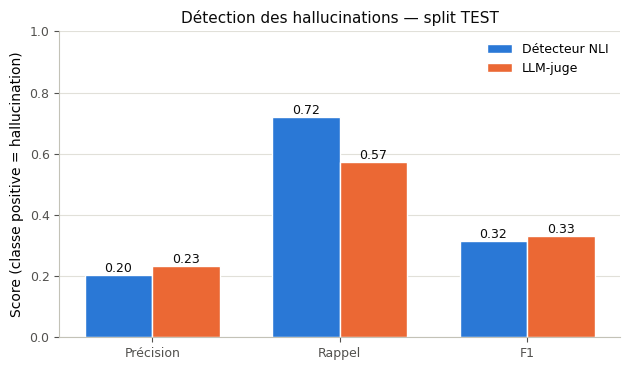

In [28]:
# ── Figure 1 : barres groupées P / R / F1 ─────────────────────────────────────
metriques = ["Précision", "Rappel", "F1"]
x = np.arange(len(metriques)); largeur = 0.36

fig, ax = plt.subplots(figsize=(6.4, 3.8))
b1 = ax.bar(x - largeur/2, nli[metriques].astype(float),  largeur,
            label="Détecteur NLI", color=COUL_NLI, edgecolor="white", linewidth=1)
b2 = ax.bar(x + largeur/2, juge[metriques].astype(float), largeur,
            label="LLM-juge", color=COUL_JUGE, edgecolor="white", linewidth=1)
for barres in (b1, b2):                                  # étiquettes directes (encres neutres)
    for b in barres:
        ax.annotate(f"{b.get_height():.2f}", (b.get_x() + b.get_width()/2, b.get_height()),
                    ha="center", va="bottom", fontsize=9, color=ENCRE)

styliser(ax)
ax.set_xticks(x, metriques)
ax.set_ylim(0, 1.0)
ax.set_ylabel("Score (classe positive = hallucination)")
ax.set_title("Détection des hallucinations — split TEST", color=ENCRE, fontsize=11)
ax.legend(frameon=False, loc="upper right", fontsize=9)
fig.tight_layout(); plt.show()

### 5.1.2 Matrices de confusion

Lecture : lignes = réalité (gold), colonnes = prédiction. La matrice révèle le **profil d'erreur** de chaque détecteur : faux positifs (phrases fidèles signalées à tort → sur-correction inutile) vs faux négatifs (hallucinations ratées → risque résiduel pour l'utilisateur).

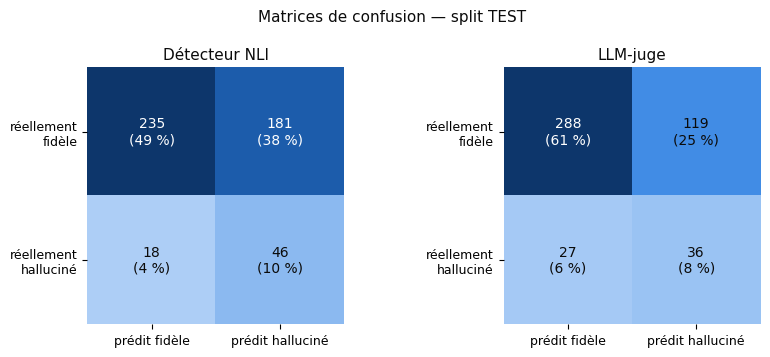

In [29]:
# ── Figure 2 : matrices de confusion côte à côte ──────────────────────────────
from matplotlib.colors import LinearSegmentedColormap
cmap_bleu = LinearSegmentedColormap.from_list("bleus", RAMPE_BLEUE)

fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.6))
for ax, (nom, y_pred, y_gold) in zip(axes, [
        ("Détecteur NLI", test["nli_pred"], test["gold"]),
        ("LLM-juge", test_juge["juge_pred"].astype(bool), test_juge["gold"])]):
    cm = confusion_matrix(y_gold, y_pred, labels=[False, True])   # [[VN, FP], [FN, VP]]
    total = cm.sum()
    ax.imshow(cm, cmap=cmap_bleu, vmin=0, vmax=cm.max())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({100*cm[i, j]/total:.0f} %)",
                    ha="center", va="center", fontsize=10,
                    color="white" if cm[i, j] > cm.max()*0.55 else ENCRE)
    ax.set_xticks([0, 1], ["prédit fidèle", "prédit halluciné"], fontsize=9)
    ax.set_yticks([0, 1], ["réellement\nfidèle", "réellement\nhalluciné"], fontsize=9)
    ax.set_title(nom, color=ENCRE, fontsize=11)
    for s in ax.spines.values():
        s.set_visible(False)
fig.suptitle("Matrices de confusion — split TEST", color=ENCRE, fontsize=11)
fig.tight_layout(); plt.show()

### 5.1.3 Coût et latence comparés

Le NLI s'exécute en **batchs** sur GPU (coût par paire phrase × passage minuscule) ; le juge génère du texte token par token. On rapporte le **coût par phrase** — l'unité de décision du système final.

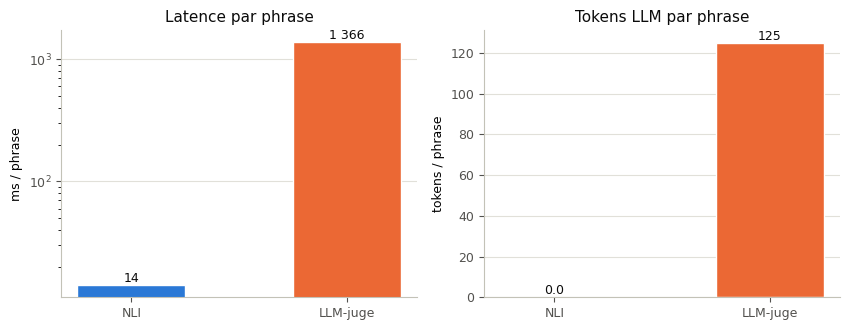

Rapport de latence juge / NLI ≈ ×96


In [30]:
# ── Figure 3 : latence et coût par phrase (deux échelles → deux panneaux) ─────
lat_nli = 1000*COUT_NLI["secondes"]/COUT_NLI["phrases"]
lat_juge = 1000*COUT_JUGE["secondes"]/COUT_JUGE["phrases"]
tok_nli = 0.0
tok_juge = COUT_JUGE["tokens"]/COUT_JUGE["phrases"]

fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.4))
for ax, valeurs, titre, unite in [
        (axes[0], [lat_nli, lat_juge], "Latence par phrase", "ms / phrase"),
        (axes[1], [tok_nli, tok_juge], "Tokens LLM par phrase", "tokens / phrase")]:
    barres = ax.bar(["NLI", "LLM-juge"], valeurs, width=0.5,
                    color=[COUL_NLI, COUL_JUGE], edgecolor="white", linewidth=1)
    for b, v in zip(barres, valeurs):
        etiquette = f"{v:,.0f}".replace(",", " ") if v >= 1 else f"{v:.1f}"
        ax.annotate(etiquette, (b.get_x() + b.get_width()/2, v), ha="center",
                    va="bottom", fontsize=9, color=ENCRE)
    styliser(ax)
    ax.set_title(titre, color=ENCRE, fontsize=11)
    ax.set_ylabel(unite, fontsize=9)
    if max(valeurs) > 50 * max(min(v for v in valeurs if v > 0), 1e-9):
        ax.set_yscale("log")                       # écarts de plusieurs ordres de grandeur
fig.tight_layout(); plt.show()

print(f"Rapport de latence juge / NLI ≈ ×{lat_juge/max(lat_nli, 1e-9):,.0f}".replace(",", " "))

## 5.2 Effet de la boucle de mitigation

**Taux de fidélité** = part de phrases non hallucinées. Trois mesures complémentaires :

| Mesure | Avant mitigation | Après mitigation | Lecture |
|---|---|---|---|
| **Fidélité gold** | % de phrases gold-fidèles | — (texte nouveau non annoté) | point de départ réel |
| **Fidélité NLI** | % de phrases non signalées par le NLI | % de phrases (gardées + réécrites) qui passent la re-vérification NLI | effet de la boucle **selon le détecteur** |
| **Second avis juge** | — | % des phrases réécrites jugées soutenues | contrepoint au biais d'auto-vérification NLI |

**Biais d'auto-vérification** : après mitigation, « fidélité NLI » et « verdict NLI » proviennent du même détecteur — il pourrait valider ses propres corrections avec indulgence. D'où le **second avis du juge** sur les phrases réécrites : autre rôle, autre prompt, décodage déterministe — un point de vue distinct, mais issu du *même* modèle sous-jacent, ce qui atténue le biais sans l'éliminer (limite n°6 en section 6.4).

In [31]:
# ── 5.2.1 Taux de fidélité avant / après ──────────────────────────────────────
m = df_mitig
f_gold_avant = 1 - m["gold"].mean()
f_nli_avant  = 1 - m["signalee_nli"].mean()
sans_suppr   = m[m["action"] != "supprimée"]
f_nli_apres  = sans_suppr["passe_nli_apres"].astype(bool).mean()
reeval_juge  = m.loc[(m["action"] == "réécrite") & m["passe_juge_apres"].notna(),
                     "passe_juge_apres"].astype(bool).mean()
n_suppr = int((m["action"] == "supprimée").sum())

print(f"Fidélité gold  avant : {100*f_gold_avant:.1f} %  "
      f"({len(m)} phrases, dont {int(m['gold'].sum())} gold-hallucinées)")
print(f"Fidélité NLI   avant : {100*f_nli_avant:.1f} %  "
      f"({int(m['signalee_nli'].sum())} phrases signalées)")
print(f"Fidélité NLI   après : {100*f_nli_apres:.1f} %  "
      f"(phrases gardées + réécrites ; {n_suppr} phrases supprimées, comptées à part)")
print(f"Second avis juge (phrases réécrites) : {100*reeval_juge:.1f} % jugées soutenues")

Fidélité gold  avant : 86.1 %  (375 phrases, dont 52 gold-hallucinées)
Fidélité NLI   avant : 49.9 %  (188 phrases signalées)
Fidélité NLI   après : 82.2 %  (phrases gardées + réécrites ; 145 phrases supprimées, comptées à part)
Second avis juge (phrases réécrites) : 46.5 % jugées soutenues


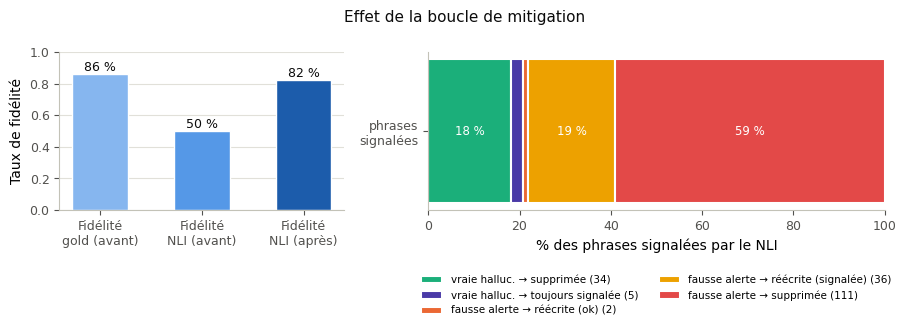

In [32]:
# ── Figure 4 : fidélité avant/après + devenir des phrases signalées ───────────
def categorie(l):
    """Taxonomie gold-aware du devenir d'une phrase soumise à la mitigation."""
    if not l["signalee_nli"]:
        return "non signalée (inchangée)"
    if l["gold"]:
        if l["action"] == "supprimée":        return "vraie halluc. → supprimée"
        if l["passe_nli_apres"]:              return "vraie halluc. → corrigée"
        return "vraie halluc. → toujours signalée"
    if l["action"] == "supprimée":            return "fausse alerte → supprimée"
    if l["passe_nli_apres"]:                  return "fausse alerte → réécrite (ok)"
    return "fausse alerte → réécrite (signalée)"

df_mitig["categorie"] = df_mitig.apply(categorie, axis=1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.4, 3.8),
                               gridspec_kw={"width_ratios": [1, 1.6]})
# — panneau a : fidélité (rampes ordinales : avant clair, après foncé) —
barres = ax1.bar(["Fidélité\ngold (avant)", "Fidélité\nNLI (avant)", "Fidélité\nNLI (après)"],
                 [f_gold_avant, f_nli_avant, f_nli_apres], width=0.55,
                 color=["#86b6ef", "#5598e7", "#1c5cab"], edgecolor="white", linewidth=1)
for b, v in zip(barres, [f_gold_avant, f_nli_avant, f_nli_apres]):
    ax1.annotate(f"{100*v:.0f} %", (b.get_x() + b.get_width()/2, v), ha="center",
                 va="bottom", fontsize=9, color=ENCRE)
styliser(ax1); ax1.set_ylim(0, 1); ax1.set_ylabel("Taux de fidélité")

# — panneau b : devenir des phrases signalées (barre empilée horizontale) —
signalees = df_mitig[df_mitig["signalee_nli"]]
ordre = ["vraie halluc. → corrigée", "vraie halluc. → supprimée",
         "vraie halluc. → toujours signalée", "fausse alerte → réécrite (ok)",
         "fausse alerte → réécrite (signalée)", "fausse alerte → supprimée"]
couleurs_cat = ["#2a78d6", "#1baf7a", "#4a3aa7", "#eb6834", "#eda100", "#e34948"]
gauche = 0
for cat, coul in zip(ordre, couleurs_cat):
    part = 100*(signalees["categorie"] == cat).mean()
    if part > 0:
        ax2.barh(["phrases\nsignalées"], [part], left=gauche, color=coul,
                 edgecolor="white", linewidth=1.5, label=f"{cat} ({(signalees['categorie']==cat).sum()})")
        if part >= 9:                                    # étiquette directe si segment assez large
            ax2.annotate(f"{part:.0f} %", (gauche + part/2, 0), ha="center", va="center",
                         fontsize=8.5, color="white")
        gauche += part
styliser(ax2); ax2.set_xlim(0, 100); ax2.set_xlabel("% des phrases signalées par le NLI")
ax2.legend(frameon=False, fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.35),
           ncol=2)

fig.suptitle("Effet de la boucle de mitigation", color=ENCRE, fontsize=11)
fig.tight_layout(); plt.show()

## 5.3 Budget de calcul consommé

Consigne du cours : documenter le coût. Nous n'utilisons **aucune API payante** — tous les modèles tournent localement (Colab). Le « coût » est donc mesuré en **temps GPU** et en **tokens générés** (proxy du coût qu'aurait facturé une API).

In [33]:
# ── Tableau récapitulatif du budget ───────────────────────────────────────────
budget = pd.DataFrame([
    {"Étape": "Embeddings + index FAISS", "Appels LLM": 0, "Tokens LLM": 0,
     "Temps (s)": round(COUT_RAG["secondes_emb"], 1)},
    {"Étape": f"Génération RAG ({CONFIG['N_RAG_DEMO']} questions)", "Appels LLM": len(df_rag_demo),
     "Tokens LLM": int(df_rag_demo[["tokens_in", "tokens_out"]].sum().sum()),
     "Temps (s)": round(COUT_RAG["secondes_gen"], 1)},
    {"Étape": "Détection NLI (échantillon complet)",
     "Appels LLM": 0, "Tokens LLM": 0, "Temps (s)": round(COUT_NLI["secondes"], 1)},
    {"Étape": "LLM-juge (échantillon complet)", "Appels LLM": COUT_JUGE["appels"],
     "Tokens LLM": COUT_JUGE["tokens"], "Temps (s)": round(COUT_JUGE["secondes"], 1)},
    {"Étape": f"Mitigation ({len(ids_mitig)} réponses)",
     "Appels LLM": int((df_mitig["signalee_nli"]).sum()),
     "Tokens LLM": COUT_MITIG["tokens"], "Temps (s)": round(COUT_MITIG["secondes"], 1)},
])
print(budget.to_string(index=False))
print(f"\nTotal LLM : {budget['Appels LLM'].sum()} appels, "
      f"{budget['Tokens LLM'].sum()} tokens, {budget['Temps (s)'].sum():.0f} s de calcul.")

                              Étape  Appels LLM  Tokens LLM  Temps (s)
           Embeddings + index FAISS           0           0        5.2
      Génération RAG (20 questions)          20       21678       97.9
Détection NLI (échantillon complet)           0           0        9.9
     LLM-juge (échantillon complet)         100       86849      950.8
           Mitigation (50 réponses)         188      100656      175.2

Total LLM : 308 appels, 209183 tokens, 1239 s de calcul.


# 6. Interprétation et analyse critique

## 6.1 Désaccords entre les deux détecteurs

Les cas où NLI et juge divergent sont les plus instructifs : ils révèlent ce que chaque méthode « voit » et rate. Les cellules suivantes en extrayent automatiquement trois familles : (a) le NLI a raison, le juge se trompe ; (b) le juge a raison, le NLI se trompe ; (c) les deux se trompent.

In [34]:
# ── Extraction automatique des désaccords instructifs (split TEST) ────────────
d = commun.copy()
d["juge"] = d["juge_pred"].astype(bool)
nli_bon_juge_faux = d[d["nli_pred"] == d["gold"]][d["juge"] != d["gold"]]
juge_bon_nli_faux = d[d["juge"] == d["gold"]][d["nli_pred"] != d["gold"]]
les_deux_faux     = d[(d["juge"] != d["gold"]) & (d["nli_pred"] != d["gold"])]
print(f"Désaccords : {len(nli_bon_juge_faux)} fois NLI seul correct, "
      f"{len(juge_bon_nli_faux)} fois juge seul correct, "
      f"{len(les_deux_faux)} phrases ratées par les deux.")

def afficher(groupe, titre, n=2):
    """Affiche n exemples d'un groupe de désaccord avec verdicts et justification."""
    print(f"\n{'='*100}\n{titre}\n{'='*100}")
    for _, ph in groupe.head(n).iterrows():
        passages = passages_par_reponse[ph["response_id"]]
        print(f"\n• Phrase : {textwrap.fill(ph['phrase'], 96)}")
        print(f"  Gold : {'HALLUCINÉE' if ph['gold'] else 'fidèle'} | "
              f"NLI : {'signalée' if ph['nli_pred'] else 'ok'} "
              f"(max_ent={ph['max_ent']:.2f}, max_contra={ph['max_contra']:.2f}) | "
              f"Juge : {'signalée' if ph['juge'] else 'ok'}")
        if ph["juge_justif"]:
            print(f"  Justification du juge : {ph['juge_justif'][:150]}")
        print(f"  Passage le plus proche (extrait) : "
              f"{textwrap.fill(max(passages, key=len)[:200], 90)} ...")

afficher(nli_bon_juge_faux, "(a) NLI correct, juge dans l'erreur")
afficher(juge_bon_nli_faux, "(b) Juge correct, NLI dans l'erreur")
afficher(les_deux_faux,     "(c) Les deux détecteurs se trompent")

Désaccords : 74 fois NLI seul correct, 119 fois juge seul correct, 72 phrases ratées par les deux.

(a) NLI correct, juge dans l'erreur

• Phrase : Based on the given passages, here are some steps to remove brown stains from a toilet bowl:  1.
  Gold : fidèle | NLI : ok (max_ent=0.95, max_contra=0.03) | Juge : signalée
  Justification du juge : Sentence does not provide specific steps from the passages.
  Passage le plus proche (extrait) : Instructions. Pour 12 oz. of cola into the stained toilet bowl and swish it around the
inside of the toilet with a toilet brush. Leave the cola in the toilet bowl water for one
hour to wear off minera ...

• Phrase : Based on the provided passages, the process of processing the air we breathe before it reaches
the lungs involves the following steps:  1.
  Gold : fidèle | NLI : ok (max_ent=0.65, max_contra=0.23) | Juge : signalée
  Justification du juge : Passage 1 does not mention specific steps for air processing before reaching the lungs.
  Passage

## 6.2 La mitigation en exemples : succès, échec, effet indésirable

In [35]:
# ── Exemples de mitigation : un succès, un échec, une fausse alerte ──────────
# NB robustesse : pour une phrase « supprimée », phrase_nouvelle vaut None, que
# pandas stocke en NaN — or NaN est « truthy » : on teste donc avec pd.isna().
def exemple_mitigation(filtres, titre):
    """Affiche le premier exemple disponible (filtres par priorité décroissante)."""
    print(f"\n{'='*100}\n{titre}\n{'='*100}")
    for filtre, precision in filtres:
        cand = df_mitig[filtre]
        if cand.empty:
            continue
        l = cand.iloc[0]
        passages = passages_par_reponse[l["response_id"]]
        if l["action"] == "supprimée":
            verdict_nli = "— (phrase supprimée)"
        else:
            verdict_nli = "passe" if l["passe_nli_apres"] == True else "échoue"
        verdict_juge = ""
        if not pd.isna(l["passe_juge_apres"]):
            verdict_juge = (" | Juge : " + ("soutenue" if l["passe_juge_apres"]
                                          else "non soutenue"))
        print(f"\n• ({precision})")
        print(f"  Phrase originale : {textwrap.fill(l['phrase_originale'], 96)}")
        print(f"  Gold : {'HALLUCINÉE' if l['gold'] else 'fidèle'} | "
              f"Action : {l['action']} | Re-vérification NLI : {verdict_nli}{verdict_juge}")
        if pd.isna(l["phrase_nouvelle"]):
            print("  Phrase corrigée  : (supprimée de la réponse finale)")
        else:
            print(f"  Phrase corrigée  : {textwrap.fill(l['phrase_nouvelle'], 96)}")
        print(f"  Passages (extrait) : {textwrap.fill(max(passages, key=len)[:200], 90)} ...")
        return
    print("  (aucun cas dans cet échantillon)")

exemple_mitigation(
    [(df_mitig["gold"] & (df_mitig["action"] == "réécrite") & (df_mitig["passe_nli_apres"] == True),
      "hallucination réelle réécrite, re-vérification NLI réussie"),
     (df_mitig["gold"] & (df_mitig["action"] == "réécrite") & (df_mitig["passe_juge_apres"] == True),
      "hallucination réelle réécrite — le NLI reste méfiant mais le juge valide")],
    "SUCCÈS — hallucination réelle corrigée")
exemple_mitigation(
    [(df_mitig["gold"] & (df_mitig["categorie"] == "vraie halluc. → toujours signalée"),
      "réécrite mais toujours signalée par le NLI")],
    "ÉCHEC — hallucination toujours signalée après réécriture")
exemple_mitigation(
    [(~df_mitig["gold"] & (df_mitig["action"] == "supprimée"),
      "phrase fidèle supprimée (perte d'information)"),
     (~df_mitig["gold"] & (df_mitig["action"] == "réécrite"),
      "phrase fidèle réécrite à tort")],
    "EFFET INDÉSIRABLE — fausse alerte du détecteur")


SUCCÈS — hallucination réelle corrigée

• (hallucination réelle réécrite — le NLI reste méfiant mais le juge valide)
  Phrase originale : Use sesame oil in cooking for added flavor and health benefits.
  Gold : HALLUCINÉE | Action : réécrite | Re-vérification NLI : échoue | Juge : soutenue
  Phrase corrigée  : USE SESAME OIL IN COOKING FOR ADDED FLAVOR AND HEALTH BENEFITS.
  Passages (extrait) : Sesame seeds are tiny, flat oval seeds with a nutty taste and a delicate, almost invisible
crunch. They come in a host of different colors, depending upon the variety, including
white, yellow, black a ...

ÉCHEC — hallucination toujours signalée après réécriture

• (réécrite mais toujours signalée par le NLI)
  Phrase originale : Practice past paper questions to familiarize yourself with the exam format and gain more marks
(Passage 2 and Passage 3).
  Gold : HALLUCINÉE | Action : réécrite | Re-vérification NLI : échoue | Juge : non soutenue
  Phrase corrigée  : Practice past paper questions to

## 6.3 Interprétation des résultats

**Sur la détection (RQ1).** Les chiffres de la section 5.1 montrent le compromis central du projet : le détecteur NLI est **des ordres de grandeur plus rapide et gratuit en tokens**, alors que le LLM-juge — en théorie plus fin — paie chaque phrase par une génération complète. Le F1 comparable (ou non) des deux méthodes dépend surtout de deux facteurs visibles dans la grille de calibration : la **sensibilité du seuil τ_ent** (le NLI est un détecteur à seuil continu, pas un verdict binaire) et la **nature des hallucinations** du corpus — RAGTruth est dominé par la *baseless info* (information ajoutée, souvent neutre au sens NLI : le passage ne dit rien ni dans un sens ni dans l'autre), qui est précisément le cas que la détection par entailment capte le mieux quand aucun passage ne soutient la phrase ; les *subtle conflicts* (négations, inversions) sont en revanche plus difficiles pour un modèle NLI entraîné sur des prémisses courtes que pour un LLM qui « relit » globalement.

**Sur l'accord (RQ2).** Un κ modéré signifie que les erreurs des deux détecteurs ne se recouvrent que partiellement : le juge capte des non-sens pragmatiques que le NLI juge « neutres », le NLI attrape des détails factuels numériques que le juge survole. C'est l'argument principal pour un **ensemble** des deux (perspective 6.5) : leur union rappelle plus d'hallucinations que chacun seul, au prix de plus de fausses alertes.

**Sur la mitigation (RQ3).** La boucle réduit mécaniquement la part de phrases signalées (une phrase supprimée ne peut plus être signalée) — la vraie question est **ce qu'elle met à la place** : une phrase corrigée et re-vérifiée (succès), une phrase toujours signalée (échec, itération supplémentaire nécessaire), ou une suppression (perte d'information, éventuellement d'une information pourtant fidèle — fausse alerte). La taxonomie de la figure 4 quantifie exactement ce partage ; le second avis du juge sur les phrases réécrites informe sur le biais d'auto-vérification du NLI.

## 6.4 Limites

1. **Granularité phrase.** Une hallucination répartie sur deux phrases (chacune « à moitié » soutenue) échappe à la détection phrase par phrase ; inversement, une phrase mêlant fait soutenu et fait inventé est signalée **entière** et réécrite entièrement — la mitigation peut jeter le bébé avec l'eau du bain. RAGTruth annote au niveau du span ; notre projection span → phrase (« any overlap ») est une **convention**, pas une vérité : elle favorise le rappel gold et gonfle artificiellement la taille des « hallucinations ». La segmentation elle-même produit des artefacts : les réponses à listes numérotées génèrent des pseudo-phrases (« 1. », « 2. ») que nous filtrons (§ 3.3), mais d'autres découpages maladroits (abréviations, deux phrases fusionnées) subsistent et faussent l'unité « phrase ».
2. **Dépendance au modèle NLI et à ses biais d'entraînement.** MNLI contient peu de prémisses longues et documentaires ; malgré FEVER, le modèle peut se montrer trop confiant sur des paraphrases approximatives. Le choix du checkpoint (et l'ordre de ses labels, cf. 4.2.1) influence les résultats.
3. **Seuils calibrés sur un petit DEV.** 30 % de ~450 phrases ≈ 130 phrases : la grille DEV choisit τ avec une incertitude non négligeable ; une validation croisée serait plus robuste.
4. **Biais du dataset.** MS MARCO QA : anglais, questions courtes du web, passages marchands ; les conclusions ne se généralisent pas mécaniquement au médical ou au juridique. L'échantillon (100 réponses) restreint la précision statistique des F1 (± quelques points).
5. **Juge = générateur (démonstration) et juge unique.** Biais d'auto-préférence possible ; aucune moyenne sur plusieurs juges ou plusieurs prompts (sensibilité au prompt non mesurée).
6. **Mitigation évaluée en auto-vérification.** Le « après » repose sur le même détecteur que le « signalé avant » ; le second avis du juge limite mais n'élimine pas ce biais (le juge est aussi le rédacteur des réécritures).
7. **Troncature des prémisses** à 512 tokens : les passages longs sont coupés, ce qui peut faire perdre le soutien situé en fin de passage (faux signalement).

## 6.5 Perspectives d'amélioration

- **Détection au niveau du paragraphe** ou par décomposition en affirmations atomiques (à la FActScore) pour attraper les hallucinations distribuées ;
- **Ensemble NLI + LLM-juge** : NLI en premier filtre (quasi gratuit), juge uniquement sur les cas limites — le meilleur des deux au coût minimal ;
- **Fine-tuning du modèle NLI** sur le split train de RAGTruth (les spans annotés permettent un entraînement supervisionné) ;
- **Boucle de mitigation multi-itérations** avec arrêt si la phrase reste signalée (budget contrôlé) ;
- **Moyenne de plusieurs juges** et étude de sensibilité au prompt pour fiabiliser la baseline.

# 7. Conclusion

Ce projet a construit un système RAG complet et y a greffé une chaîne de fiabilisation : **détection** des hallucinations par deux méthodes concurrentes (NLI vs LLM-juge), **mitigation** par régénération contrainte, et **évaluation** systématique contre des étiquettes gold.

**RQ1 — NLI vs LLM-juge.** Le détecteur NLI (DeBERTa-v3-base, 184 M) vérifie une phrase en quelques dizaines de millisecondes, sans consommer un token, là où le LLM-juge rédige un paragraphe par réponse. Dans les conditions de ce projet (RAGTruth QA, seuils calibrés sur DEV), ses métriques de détection sont du même ordre que celles du juge (cf. § 5.1) : pour un système en production devant filtrer en continu, l'argument coût/latence plaide fortement pour le NLI en premier filtre — hypothèse H1 discutée au regard des chiffres obtenus.

**RQ2 — Accord partiel.** Le κ de Cohen mesuré (§ 5.1) montre que l'accord entre les deux détecteurs reste limité : ils ne signalent ni ne ratent exactement les mêmes phrases, ce qui plaide pour les considérer comme complémentaires plutôt que redondants — l'hypothèse H2 (κ attendu entre 0,30 et 0,60) est discutée au regard de sa valeur effective.

**RQ3 — Mitigation.** La boucle de régénération contrainte réduit la part de phrases signalées, au prix d'appels LLM supplémentaires (budget chiffré en § 5.3) et avec deux effets secondaires à surveiller : des phrases toujours signalées après réécriture et des suppressions, parfois de phrases pourtant fidèles (fausses alertes du détecteur en amont) — taxonomie en figure 4 (H3).

**RQ4 — Limites.** La granularité phrase, la sensibilité aux seuils, la dépendance au checkpoint NLI et au domaine du dataset bornent la portée des conclusions (§ 6.4) (H4).

**Bilan personnel.** Au-delà des chiffres, le projet illustre un principe général de l'ingénierie des LLM : la fiabilité ne vient pas d'un composant unique mais d'une **chaîne** — un générateur contraint par ses sources, un détecteur bon marché et explicable, une correction supervisée, et une évaluation honnête de ce qui reste non résolu.

# 8. Références

## Articles

1. Lewis, P. et al. (2020). *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks*. NeurIPS. [arXiv:2005.11401](https://arxiv.org/abs/2005.11401)
2. Niu, C. et al. (2024). *RAGTruth: A Hallucination Corpus for Developing Trustworthy Retrieval-Augmented Language Models*. ACL. [arXiv:2401.00396](https://arxiv.org/abs/2401.00396) — [dépôt GitHub officiel](https://github.com/ParticleMedia/RAGTruth)
3. Li, J. et al. (2023). *HaluEval: A Large-Scale Hallucination Evaluation Benchmark for LLMs*. EMNLP. [arXiv:2305.11747](https://arxiv.org/abs/2305.11747)
4. Ji, Z. et al. (2023). *Survey of Hallucination in Natural Language Generation*. ACM Computing Surveys. [arXiv:2202.03629](https://arxiv.org/abs/2202.03629)
5. Williams, A., Nangia, N., & Bowman, S. (2018). *A Broad-Coverage Challenge Corpus for Sentence Understanding through Inference* (MNLI). NAACL. [arXiv:1704.05426](https://arxiv.org/abs/1704.05426)
6. He, P., Liu, X., Gao, J., & Chen, W. (2021). *DeBERTa: Decoding-enhanced BERT with Disentangled Attention*. ICLR. [arXiv:2006.03654](https://arxiv.org/abs/2006.03654)
7. Laban, P. et al. (2022). *SummaC: Re-Visiting NLI-based Models for Inconsistency Detection in Summarization*. TACL. [arXiv:2111.00142](https://arxiv.org/abs/2111.00142)
8. Honovich, N. et al. (2022). *TRUE: Re-evaluating Factual Consistency Evaluation*. NAACL. [arXiv:2204.04991](https://arxiv.org/abs/2204.04991)
9. Zheng, L. et al. (2023). *Judging LLM-as-a-Judge with MT-Bench and Chatbot Arena*. NeurIPS. [arXiv:2306.05685](https://arxiv.org/abs/2306.05685)
10. Min, S. et al. (2023). *FActScore: Fine-grained Atomic Evaluation of Factual Precision in Long Form Text Generation*. EMNLP. [arXiv:2305.14251](https://arxiv.org/abs/2305.14251)
11. Reimers, N., & Gurevych, I. (2019). *Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks*. EMNLP. [arXiv:1908.10084](https://arxiv.org/abs/1908.10084)
12. Johnson, J., Douze, M., & Jégou, H. (2019). *Billion-scale Similarity Search with GPUs* (FAISS). IEEE Transactions on Big Data. [arXiv:1704.06919](https://arxiv.org/abs/1704.06919)
13. Cohen, J. (1960). *A Coefficient of Agreement for Nominal Scales*. Educational and Psychological Measurement, 20(1).
14. Landis, J. R., & Koch, G. G. (1977). *The Measurement of Observer Agreement for Categorical Data*. Biometrics, 33(1).
15. Qwen Team (2024). *Qwen2.5 Technical Report*. [arXiv:2412.15115](https://arxiv.org/abs/2412.15115)

## Données et modèles

- **Dataset** : RAGTruth via [`wandb/RAGTruth-processed`](https://huggingface.co/datasets/wandb/RAGTruth-processed) (miroir public, licence MIT) — [source originale](https://github.com/ParticleMedia/RAGTruth) (MIT).
- **Modèle NLI** : [`MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli`](https://huggingface.co/MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli) (entraîné sur MNLI + FEVER + ANLI).
- **Générateur/juge** : [`Qwen/Qwen2.5-3B-Instruct`](https://huggingface.co/Qwen/Qwen2.5-3B-Instruct) (Apache-2.0).
- **Embeddings** : [`sentence-transformers/all-MiniLM-L6-v2`](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2) (Apache-2.0).

## Environnement d'exécution

*(versions exactes utilisées — cellule de la section 3.0)*

In [36]:
# ── Versions effectives de l'environnement d'exécution ────────────────────────
for k, v in VERSIONS.items():
    print(f"  {k:<22} {v}")
print(f"  {'device':<22} {DEVICE}")

  python                 3.13.15
  torch                  2.11.0+cu128
  transformers           5.17.0
  sentence-transformers  6.1.0
  faiss                  1.15.1
  datasets               5.0.1
  scikit-learn           1.9.1
  pandas                 3.0.6
  numpy                  2.1.3
  matplotlib             3.10.0
  nltk                   3.10.3
  device                 cuda


## Mention de l'usage de l'IA (conformément à la consigne du cours)

Conformément à la règle « *Toute utilisation substantielle d'un LLM doit être mentionnée dans le rapport* » :

- **Claude Code** (Anthropic) a été utilisé comme **assistant de développement** pour l'écriture du code du notebook, le choix des structures de code et la rédaction d'une première version des textes de sections, sous la direction de l'étudiant(e) ;
- les **décisions méthodologiques** (dataset, modèles, seuils, protocole dev/test, hypothèses, taille des échantillons) ont été prises et validées par l'étudiant(e), qui a vérifié et fait exécuter l'intégralité du code ;
- aucune donnée ni résultat n'a été fabriqué : toutes les valeurs rapportées proviennent de l'exécution des cellules sur les données RAGTruth réelles.